# Analytical Part

This notebook consolidates the cleaned BLE supply balance data and derived indicators for barley, potatoes and soft wheat. The objective is to prepare a validated analytical dataset for examining agricultural market resilience in Germany from 1991/92 to 2024/25.

In [8]:
# Load the processed BLE dataset and derived indicators

from pathlib import Path
import pandas as pd

project_dir = Path.cwd().parent
processed_dir = project_dir / "data" / "processed"

# Load the main dataset
df_analysis = pd.read_excel(
    processed_dir / "ble_cleaned_supply_balance_with_quotas_1991-2025.xlsx"
)

# Load derived indicators
net_trade_balance = pd.read_excel(
    processed_dir / "ble_net_trade_balance_1991-2025.xlsx"
)

production_change = pd.read_excel(
    processed_dir / "ble_production_change_1991-2025.xlsx"
)

domestic_use_change = pd.read_excel(
    processed_dir / "ble_domestic_use_change_1991-2025.xlsx"
)

# Check dataset dimensions
print("Main dataset:", df_analysis.shape)
print("Net trade balance:", net_trade_balance.shape)
print("Production changes:", production_change.shape)
print("Domestic use changes:", domestic_use_change.shape)


Main dataset: (1836, 6)
Net trade balance: (102, 5)
Production changes: (102, 5)
Domestic use changes: (102, 5)


## Preparation of the Analytical Dataset

This section extracts the key supply balance indicators and combines them with the derived metrics to create a consolidated dataset for further analysis.

In [9]:

# Extract key supply balance indicators

key_positions = [
    "Einfuhr",
    "Ausfuhr",
    "Inlandsverwendung insgesamt",
    "Inlandsverwendung",
    "Verwendbare Erzeugung",
    "Selbstversorgungsgrad in %",
]

key_data = df_analysis.loc[
    df_analysis["Bilanz Position"].isin(key_positions),
    [
        "Wirtschaftsjahr",
        "Bilanz Produkt",
        "Bilanz Position",
        "Bilanz Wert",
    ],
].copy()

print("Extracted records:", key_data.shape[0])
print("Products:", sorted(key_data["Bilanz Produkt"].unique()))
print("Balance positions:", sorted(key_data["Bilanz Position"].unique()))


Extracted records: 510
Products: ['Gerste', 'Kartoffeln', 'Weichweizen']
Balance positions: ['Ausfuhr', 'Einfuhr', 'Inlandsverwendung', 'Inlandsverwendung insgesamt', 'Selbstversorgungsgrad in %', 'Verwendbare Erzeugung']


### Reshape Supply Balance Indicators

The selected supply balance positions are reshaped into separate columns for each indicator, with one record per product and financial year.

In [10]:

# Reshape supply balance indicators into a wide format

supply_wide = key_data.pivot(
    index=["Wirtschaftsjahr", "Bilanz Produkt"],
    columns="Bilanz Position",
    values="Bilanz Wert",
).reset_index()

supply_wide.columns.name = None

print("Supply balance dataset shape:", supply_wide.shape)
print("Duplicate product-year records:",
      supply_wide.duplicated(
          subset=["Wirtschaftsjahr", "Bilanz Produkt"]
      ).sum())

display(supply_wide.head(10))


Supply balance dataset shape: (102, 8)
Duplicate product-year records: 0


,Wirtschaftsjahr,Bilanz Produkt,Ausfuhr,Einfuhr,Inlandsverwendung,Inlandsverwendung insgesamt,Selbstversorgungsgrad in %,Verwendbare Erzeugung
0,1991/92,Gerste,3537.0,1233.0,NaN,10637.0,136.26022,14494.0
1,1991/92,Kartoffeln,1002.0,1757.0,10787.0,NaN,90.00000,9737.0
2,1991/92,Weichweizen,4941.0,1440.0,NaN,11639.0,142.03110,16531.0
3,1992/93,Gerste,2725.0,1035.0,NaN,10502.0,116.13026,12196.0
4,1992/93,Kartoffeln,1122.0,1458.0,10644.0,NaN,97.00000,10358.0
5,1992/93,Weichweizen,5457.0,1660.0,NaN,11004.0,140.60342,15472.0
6,1993/94,Gerste,3315.0,1154.0,NaN,9692.0,113.55757,11006.0
7,1993/94,Kartoffeln,1090.0,1320.0,11912.0,NaN,98.00000,11633.0
8,1993/94,Weichweizen,7802.0,1637.0,NaN,12943.0,121.45561,15720.0
9,1994/95,Gerste,3251.0,1223.0,NaN,9901.0,108.57489,10750.0


### Standardization Domestic Use

Domestic use is reported under different BLE position names for potatoes and the two cereal products. These values are consolidated into a single column while preserving the original wide-format dataset.

In [11]:

# Standardize domestic use across all products

supply_base = supply_wide.copy()

supply_base["Inlandsverwendung standardisiert"] = (
    supply_base["Inlandsverwendung insgesamt"]
    .combine_first(supply_base["Inlandsverwendung"])
)

# Check the standardized values
print("Missing standardized domestic use values:",
      supply_base["Inlandsverwendung standardisiert"].isna().sum())

print("\nDomestic use values by product:")
print(
    supply_base.groupby("Bilanz Produkt")[
        "Inlandsverwendung standardisiert"
    ].agg(["count", "min", "max"])
)

display(
    supply_base[
        [
            "Wirtschaftsjahr",
            "Bilanz Produkt",
            "Inlandsverwendung standardisiert",
        ]
    ].head(9)
)


Missing standardized domestic use values: 0

Domestic use values by product:
                count          min          max
Bilanz Produkt                                 
Gerste             34   7886.53224  10815.54467
Kartoffeln         34   6253.74502  12223.00000
Weichweizen        34  11004.00000  19760.14208


,Wirtschaftsjahr,Bilanz Produkt,Inlandsverwendung standardisiert
0,1991/92,Gerste,10637.0
1,1991/92,Kartoffeln,10787.0
2,1991/92,Weichweizen,11639.0
3,1992/93,Gerste,10502.0
4,1992/93,Kartoffeln,10644.0
5,1992/93,Weichweizen,11004.0
6,1993/94,Gerste,9692.0
7,1993/94,Kartoffeln,11912.0
8,1993/94,Weichweizen,12943.0


### Creation of the Standardized Supply Dataset

This section retains the key supply balance indicators and the standardized domestic use measure in a consistent structure for all three products.

In [12]:
# Create a standardized supply dataset

supply_base = supply_base.drop(
    columns=[
        "Inlandsverwendung",
        "Inlandsverwendung insgesamt",
    ]
)

print("Standardized supply dataset shape:", supply_base.shape)
print("Duplicate product-year records:",
      supply_base.duplicated(
          subset=["Wirtschaftsjahr", "Bilanz Produkt"]
      ).sum())

display(supply_base.head())

Standardized supply dataset shape: (102, 7)
Duplicate product-year records: 0


,Wirtschaftsjahr,Bilanz Produkt,Ausfuhr,Einfuhr,Selbstversorgungsgrad in %,Verwendbare Erzeugung,Inlandsverwendung standardisiert
0,1991/92,Gerste,3537.0,1233.0,136.26022,14494.0,10637.0
1,1991/92,Kartoffeln,1002.0,1757.0,90.00000,9737.0,10787.0
2,1991/92,Weichweizen,4941.0,1440.0,142.03110,16531.0,11639.0
3,1992/93,Gerste,2725.0,1035.0,116.13026,12196.0,10502.0
4,1992/93,Kartoffeln,1122.0,1458.0,97.00000,10358.0,10644.0


In [13]:

# Merge the net trade balance into the analytical dataset

net_trade_merge = net_trade_balance[
    [
        "Wirtschaftsjahr",
        "Bilanz Produkt",
        "Nettohandelsbilanz",
    ]
].copy()

analytical_df = supply_base.merge(
    net_trade_merge,
    on=["Wirtschaftsjahr", "Bilanz Produkt"],
    how="left",
    validate="one_to_one",
    indicator=True,
)

print("Merge results:")
print(analytical_df["_merge"].value_counts())

print(
    "Missing net trade balance values:",
    analytical_df["Nettohandelsbilanz"].isna().sum(),
)

analytical_df = analytical_df.drop(columns="_merge")

print("Analytical dataset shape:", analytical_df.shape)
display(analytical_df.head())


Merge results:
_merge
both          102
left_only       0
right_only      0
Name: count, dtype: int64
Missing net trade balance values: 0
Analytical dataset shape: (102, 8)


,Wirtschaftsjahr,Bilanz Produkt,Ausfuhr,Einfuhr,Selbstversorgungsgrad in %,Verwendbare Erzeugung,Inlandsverwendung standardisiert,Nettohandelsbilanz
0,1991/92,Gerste,3537.0,1233.0,136.26022,14494.0,10637.0,2304.0
1,1991/92,Kartoffeln,1002.0,1757.0,90.00000,9737.0,10787.0,-755.0
2,1991/92,Weichweizen,4941.0,1440.0,142.03110,16531.0,11639.0,3501.0
3,1992/93,Gerste,2725.0,1035.0,116.13026,12196.0,10502.0,1690.0
4,1992/93,Kartoffeln,1122.0,1458.0,97.00000,10358.0,10644.0,-336.0


In [14]:

# Merge year-over-year production changes

production_merge = production_change[
    ["Wirtschaftsjahr", "Bilanz Produkt", "Veränderung in %"]
].copy()

production_merge = production_merge.rename(
    columns={"Veränderung in %": "Erzeugungsänderung in %"}
)

analytical_df = analytical_df.merge(
    production_merge,
    on=["Wirtschaftsjahr", "Bilanz Produkt"],
    how="left",
    validate="one_to_one",
    indicator=True,
)

print("Merge results:")
print(analytical_df["_merge"].value_counts())

print(
    "Missing production changes:",
    analytical_df["Erzeugungsänderung in %"].isna().sum(),
)

analytical_df = analytical_df.drop(columns="_merge")

print("Analytical dataset shape:", analytical_df.shape)
display(analytical_df.head())


Merge results:
_merge
both          102
left_only       0
right_only      0
Name: count, dtype: int64
Missing production changes: 3
Analytical dataset shape: (102, 9)


,Wirtschaftsjahr,Bilanz Produkt,Ausfuhr,Einfuhr,Selbstversorgungsgrad in %,Verwendbare Erzeugung,Inlandsverwendung standardisiert,Nettohandelsbilanz,Erzeugungsänderung in %
0,1991/92,Gerste,3537.0,1233.0,136.26022,14494.0,10637.0,2304.0,NaN
1,1991/92,Kartoffeln,1002.0,1757.0,90.00000,9737.0,10787.0,-755.0,NaN
2,1991/92,Weichweizen,4941.0,1440.0,142.03110,16531.0,11639.0,3501.0,NaN
3,1992/93,Gerste,2725.0,1035.0,116.13026,12196.0,10502.0,1690.0,-15.854836
4,1992/93,Kartoffeln,1122.0,1458.0,97.00000,10358.0,10644.0,-336.0,6.377734


### Add Year-over-Year Changes in Domestic Use

This section adds the annual percentage change in domestic use for each product and financial year.

In [15]:

# Merge year-over-year changes in domestic use

domestic_use_merge = domestic_use_change[
    [
        "Wirtschaftsjahr",
        "Bilanz Produkt",
        "Veränderung in %",
    ]
].copy()

domestic_use_merge = domestic_use_merge.rename(
    columns={
        "Veränderung in %": "Inlandsverwendungsänderung in %"
    }
)

analytical_df = analytical_df.merge(
    domestic_use_merge,
    on=["Wirtschaftsjahr", "Bilanz Produkt"],
    how="left",
    validate="one_to_one",
    indicator=True,
)

print("Merge results:")
print(analytical_df["_merge"].value_counts())

print(
    "\nMissing domestic use changes:",
    analytical_df["Inlandsverwendungsänderung in %"].isna().sum(),
)

analytical_df = analytical_df.drop(columns="_merge")

print("\nAnalytical dataset shape:", analytical_df.shape)
display(analytical_df.head())


Merge results:
_merge
both          102
left_only       0
right_only      0
Name: count, dtype: int64

Missing domestic use changes: 3

Analytical dataset shape: (102, 10)


,Wirtschaftsjahr,Bilanz Produkt,Ausfuhr,Einfuhr,Selbstversorgungsgrad in %,Verwendbare Erzeugung,Inlandsverwendung standardisiert,Nettohandelsbilanz,Erzeugungsänderung in %,Inlandsverwendungsänderung in %
0,1991/92,Gerste,3537.0,1233.0,136.26022,14494.0,10637.0,2304.0,NaN,NaN
1,1991/92,Kartoffeln,1002.0,1757.0,90.00000,9737.0,10787.0,-755.0,NaN,NaN
2,1991/92,Weichweizen,4941.0,1440.0,142.03110,16531.0,11639.0,3501.0,NaN,NaN
3,1992/93,Gerste,2725.0,1035.0,116.13026,12196.0,10502.0,1690.0,-15.854836,-1.269155
4,1992/93,Kartoffeln,1122.0,1458.0,97.00000,10358.0,10644.0,-336.0,6.377734,-1.325670


In [16]:

# Check whether import and export quotas are available

print("Quota positions in df_analysis:")
print(
    df_analysis.loc[
        df_analysis["Bilanz Position"].isin(
            ["Importquote in %", "Exportquote in %"]
        ),
        "Bilanz Position",
    ].value_counts()
)

print("\nCurrent analytical dataset columns:")
print(analytical_df.columns.tolist())

print("\nCurrent analytical dataset shape:")
print(analytical_df.shape)


Quota positions in df_analysis:
Series([], Name: count, dtype: int64)

Current analytical dataset columns:
['Wirtschaftsjahr', 'Bilanz Produkt', 'Ausfuhr', 'Einfuhr', 'Selbstversorgungsgrad in %', 'Verwendbare Erzeugung', 'Inlandsverwendung standardisiert', 'Nettohandelsbilanz', 'Erzeugungsänderung in %', 'Inlandsverwendungsänderung in %']

Current analytical dataset shape:
(102, 10)


### Load the Previously Calculated Quotas

The import and export quotas were calculated in the data preparation notebook and saved separately in the processed dataset. This section reloads that dataset to retrieve the quota indicators.

In [20]:

# Reload the processed dataset containing the calculated quotas

from pathlib import Path
import pandas as pd

project_dir = Path.cwd().parent
processed_dir = project_dir / "data" / "processed"

quota_source_path = (
    processed_dir
    / "ble_cleaned_supply_balance_with_quotas_1991-2025.xlsx"
)

quota_source = pd.read_excel(quota_source_path)

print("Loaded file:", quota_source_path.name)
print("Dataset shape:", quota_source.shape)

print("\nAvailable quota positions:")
print(
    quota_source.loc[
        quota_source["Bilanz Position"].isin(
            ["Importquote", "Exportquote"]
        ),
        "Bilanz Position",
    ].value_counts()
)


Loaded file: ble_cleaned_supply_balance_with_quotas_1991-2025.xlsx
Dataset shape: (1836, 6)

Available quota positions:
Bilanz Position
Importquote    102
Exportquote    102
Name: count, dtype: int64


In [21]:

# Extract and reshape the import and export quotas

quota_data = quota_source.loc[
    quota_source["Bilanz Position"].isin(
        ["Importquote", "Exportquote"]
    ),
    [
        "Wirtschaftsjahr",
        "Bilanz Produkt",
        "Bilanz Position",
        "Bilanz Wert",
    ],
].copy()

quota_wide = quota_data.pivot(
    index=["Wirtschaftsjahr", "Bilanz Produkt"],
    columns="Bilanz Position",
    values="Bilanz Wert",
).reset_index()

quota_wide.columns.name = None

quota_wide = quota_wide.rename(
    columns={
        "Importquote": "Importquote in %",
        "Exportquote": "Exportquote in %",
    }
)

print("Quota dataset shape:", quota_wide.shape)
print("Missing import quotas:", quota_wide["Importquote in %"].isna().sum())
print("Missing export quotas:", quota_wide["Exportquote in %"].isna().sum())

# Merge the quotas into the analytical dataset

analytical_df = analytical_df.merge(
    quota_wide,
    on=["Wirtschaftsjahr", "Bilanz Produkt"],
    how="left",
    validate="one_to_one",
    indicator=True,
)

print("\nMerge results:")
print(analytical_df["_merge"].value_counts())

print("\nMissing import quotas:", analytical_df["Importquote in %"].isna().sum())
print("Missing export quotas:", analytical_df["Exportquote in %"].isna().sum())

analytical_df = analytical_df.drop(columns="_merge")

print("\nAnalytical dataset shape:", analytical_df.shape)
print("\nColumns:")
print(analytical_df.columns.tolist())

display(analytical_df.head())


Quota dataset shape: (102, 4)
Missing import quotas: 0
Missing export quotas: 0

Merge results:
_merge
both          102
left_only       0
right_only      0
Name: count, dtype: int64

Missing import quotas: 0
Missing export quotas: 0

Analytical dataset shape: (102, 12)

Columns:
['Wirtschaftsjahr', 'Bilanz Produkt', 'Ausfuhr', 'Einfuhr', 'Selbstversorgungsgrad in %', 'Verwendbare Erzeugung', 'Inlandsverwendung standardisiert', 'Nettohandelsbilanz', 'Erzeugungsänderung in %', 'Inlandsverwendungsänderung in %', 'Exportquote in %', 'Importquote in %']


,Wirtschaftsjahr,Bilanz Produkt,Ausfuhr,Einfuhr,Selbstversorgungsgrad in %,Verwendbare Erzeugung,Inlandsverwendung standardisiert,Nettohandelsbilanz,Erzeugungsänderung in %,Inlandsverwendungsänderung in %,Exportquote in %,Importquote in %
0,1991/92,Gerste,3537.0,1233.0,136.26022,14494.0,10637.0,2304.0,NaN,NaN,24.403201,11.591614
1,1991/92,Kartoffeln,1002.0,1757.0,90.00000,9737.0,10787.0,-755.0,NaN,NaN,10.290644,16.288125
2,1991/92,Weichweizen,4941.0,1440.0,142.03110,16531.0,11639.0,3501.0,NaN,NaN,29.889299,12.372197
3,1992/93,Gerste,2725.0,1035.0,116.13026,12196.0,10502.0,1690.0,-15.854836,-1.269155,22.343391,9.855266
4,1992/93,Kartoffeln,1122.0,1458.0,97.00000,10358.0,10644.0,-336.0,6.377734,-1.325670,10.832207,13.697858


### Final Data Quality Checks

This section validates the completeness and consistency of the consolidated analytical dataset. It checks duplicate product-year combinations, the number of observations per product, missing values and data types before the dataset is saved.

In [22]:

# Check the final analytical dataset

print("Dataset shape:", analytical_df.shape)

# Check duplicate product-year combinations
duplicate_count = analytical_df.duplicated(
    subset=["Wirtschaftsjahr", "Bilanz Produkt"]
).sum()

print("\nDuplicate product-year records:", duplicate_count)

# Check observations per product
print("\nRecords per product:")
print(analytical_df["Bilanz Produkt"].value_counts().sort_index())

# Check unique financial years
print("\nUnique financial years:", analytical_df["Wirtschaftsjahr"].nunique())

# Check missing values
print("\nMissing values per column:")
print(analytical_df.isna().sum())

# Check data types
print("\nData types:")
print(analytical_df.dtypes)

# Check whether all analytical indicator columns are numeric
numeric_columns = [
    "Ausfuhr",
    "Einfuhr",
    "Selbstversorgungsgrad in %",
    "Verwendbare Erzeugung",
    "Inlandsverwendung standardisiert",
    "Nettohandelsbilanz",
    "Erzeugungsänderung in %",
    "Inlandsverwendungsänderung in %",
    "Exportquote in %",
    "Importquote in %",
]

print("\nNon-numeric values in indicator columns:")
print(
    analytical_df[numeric_columns]
    .apply(lambda column: pd.to_numeric(column, errors="coerce").isna().sum())
)


Dataset shape: (102, 12)

Duplicate product-year records: 0

Records per product:
Bilanz Produkt
Gerste         34
Kartoffeln     34
Weichweizen    34
Name: count, dtype: int64

Unique financial years: 34

Missing values per column:
Wirtschaftsjahr                     0
Bilanz Produkt                      0
Ausfuhr                             0
Einfuhr                             0
Selbstversorgungsgrad in %          0
Verwendbare Erzeugung               0
Inlandsverwendung standardisiert    0
Nettohandelsbilanz                  0
Erzeugungsänderung in %             3
Inlandsverwendungsänderung in %     3
Exportquote in %                    0
Importquote in %                    0
dtype: int64

Data types:
Wirtschaftsjahr                         str
Bilanz Produkt                          str
Ausfuhr                             float64
Einfuhr                             float64
Selbstversorgungsgrad in %          float64
Verwendbare Erzeugung               float64
Inlandsverwendung sta

### Saving the Final Analytical Dataset

The consolidated analytical dataset has passed the main data quality checks. It is saved as an Excel file for use in the subsequent analysis and visualisation stages.

In [23]:

# Save the final analytical dataset

output_path = (
    processed_dir
    / "ble_supply_balance_with_derived_indicators_1991-2025.xlsx"
)

analytical_df.to_excel(output_path, index=False)

print("Analytical dataset saved successfully.")
print("File:", output_path)
print("Dataset shape:", analytical_df.shape)
print("Number of products:", analytical_df["Bilanz Produkt"].nunique())
print("Number of financial years:", analytical_df["Wirtschaftsjahr"].nunique())


Analytical dataset saved successfully.
File: c:\Users\incog\Desktop\Portfolio_Project_Agriculture\data\processed\ble_supply_balance_with_derived_indicators_1991-2025.xlsx
Dataset shape: (102, 12)
Number of products: 3
Number of financial years: 34


## Visualizations - Availability and Supply Balance

This section visualizes the development of agricultural supply in Germany for barley, potatoes and soft wheat from 1991/92 to 2024/25. The analysis focuses on usable production, net trade balance and self-sufficiency to compare supply patterns across the three products.

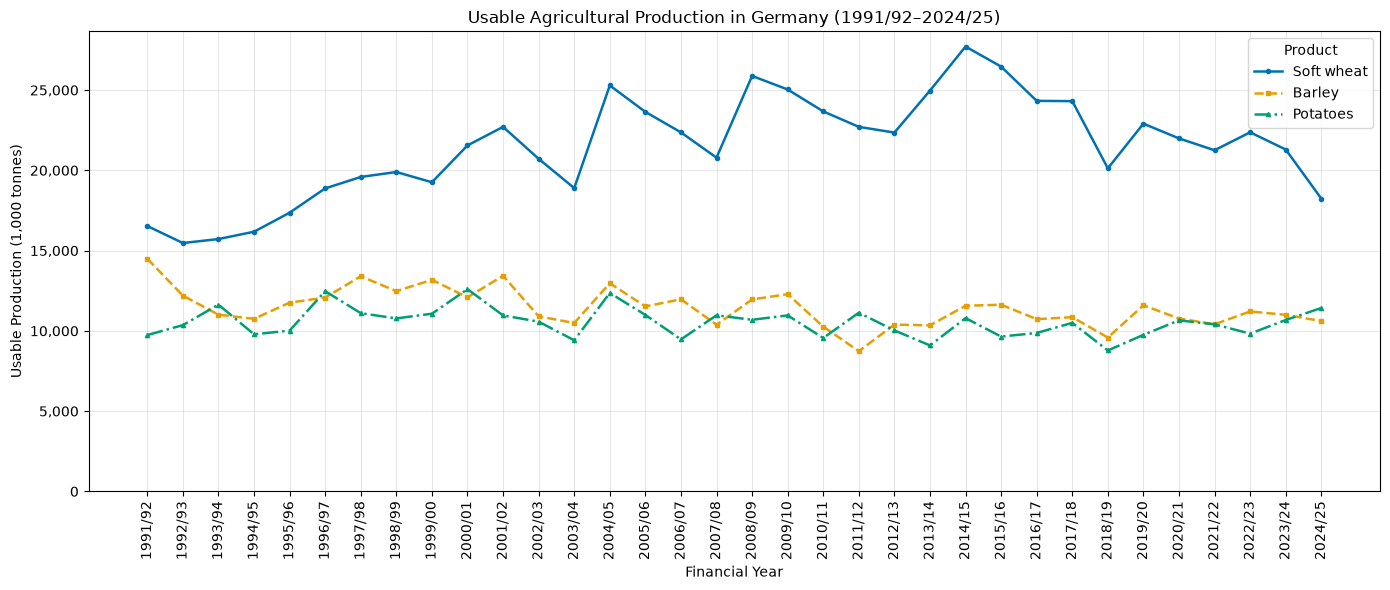

In [29]:

import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Select usable production data
production_plot = analytical_df[
    ["Wirtschaftsjahr", "Bilanz Produkt", "Verwendbare Erzeugung"]
].copy()

# Sort financial years chronologically
production_plot = production_plot.sort_values(
    by=["Bilanz Produkt", "Wirtschaftsjahr"]
)

# Define a colorblind-friendly color palette
product_styles = {
    "Weichweizen": {
        "label": "Soft wheat",
        "color": "#0072B2",
        "marker": "o",
        "linestyle": "-",
    },
    "Gerste": {
        "label": "Barley",
        "color": "#E69F00",
        "marker": "s",
        "linestyle": "--",
    },
    "Kartoffeln": {
        "label": "Potatoes",
        "color": "#009E73",
        "marker": "^",
        "linestyle": "-.",
    },
}

# Create the line chart
fig, ax = plt.subplots(figsize=(14, 6))

# Plot usable production for each product
for product, style in product_styles.items():
    product_data = production_plot[
        production_plot["Bilanz Produkt"] == product
    ]

    ax.plot(
        product_data["Wirtschaftsjahr"],
        product_data["Verwendbare Erzeugung"],
        label=style["label"],
        color=style["color"],
        marker=style["marker"],
        linestyle=style["linestyle"],
        markersize=3,
        linewidth=1.8,
    )

# Set chart title and axis labels
ax.set_title(
    "Usable Agricultural Production in Germany (1991/92–2024/25)"
)
ax.set_xlabel("Financial Year")
ax.set_ylabel("Usable Production (1,000 tonnes)")

# Format the y-axis using English thousands separators
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

# Start the y-axis at zero
ax.set_ylim(bottom=0)

# Format x-axis labels
ax.tick_params(axis="x", labelrotation=90)

# Add legend and grid
ax.legend(title="Product")
ax.grid(True, alpha=0.3)

# Improve layout
fig.tight_layout()

# Display the chart
plt.show()


In [25]:
df_analysis.loc[
    df_analysis["Bilanz Position"] == "Verwendbare Erzeugung",
    ["Bilanz Produkt", "Bilanz Einheit"]
].drop_duplicates()

,Bilanz Produkt,Bilanz Einheit
15,Gerste,1 000 t Produktgewicht
590,Kartoffeln,1 000 t Produktgewicht
1069,Weichweizen,1 000 t Produktgewicht


In [26]:

# Compare usable production levels across products
production_plot.groupby("Bilanz Produkt")[
    "Verwendbare Erzeugung"
].agg(["min", "mean", "max"]).round(0)


,min,mean,max
Bilanz Produkt,,,
Gerste,8734.0,11442.0,14494.0
Kartoffeln,8778.0,10532.0,12598.0
Weichweizen,15472.0,21484.0,27711.0


### Visualize Usable Agricultural Production and Historical Events

This section visualizes usable production for barley, potatoes and soft wheat in Germany from 1991/92 to 2024/25. The three product series are displayed as solid, color-coded lines. Historical events are indicated by shaded background periods to provide context for potential production and market disruptions.

The event markers represent historical context and do not establish causal relationships. Calendar-year events are aligned approximately with the agricultural financial-year series.

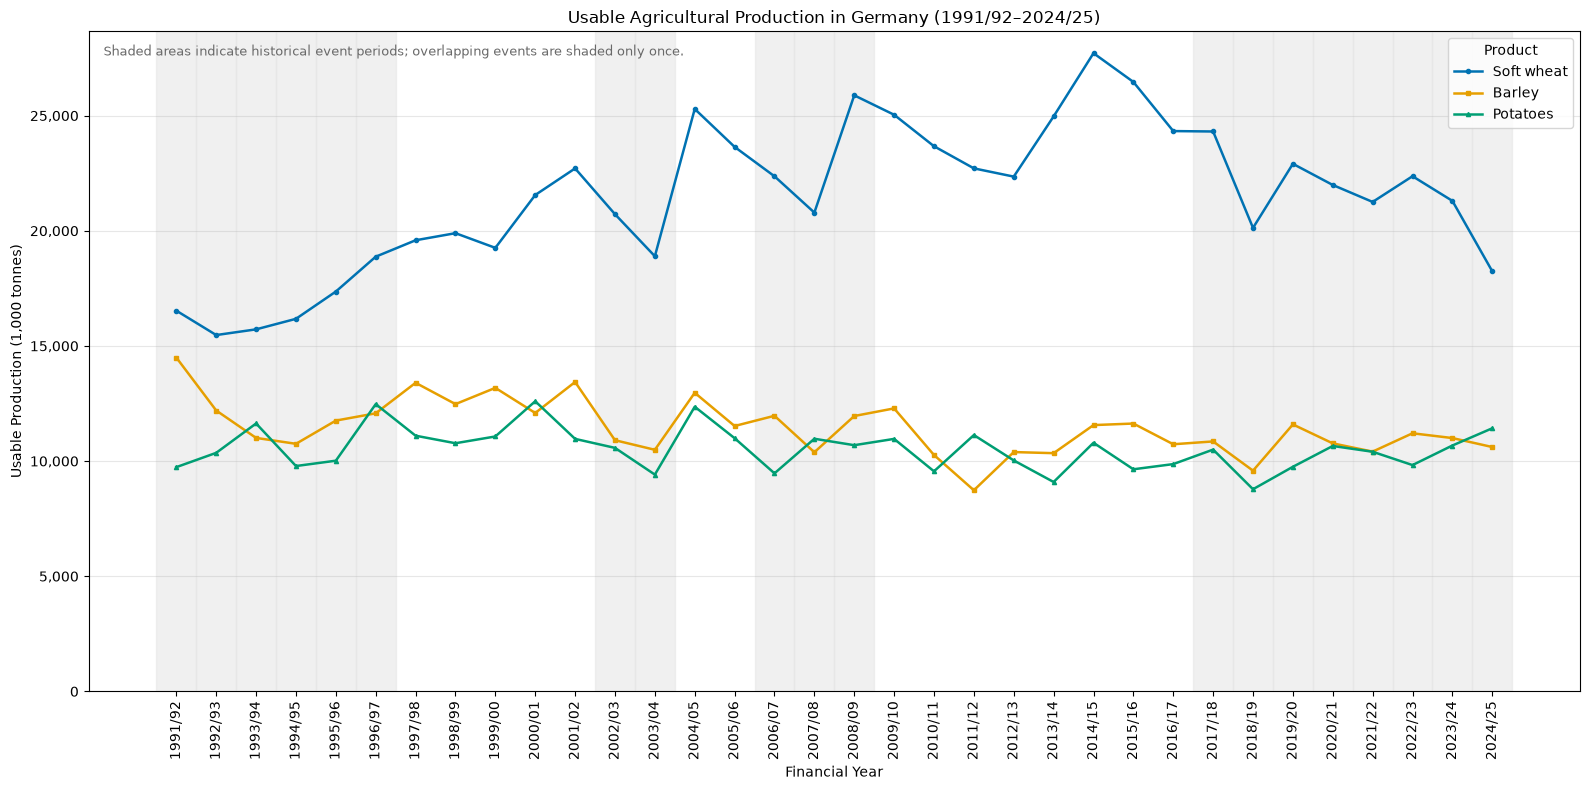

In [9]:

# Import visualization libraries
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Select usable production data
production_plot = analytical_df[
    ["Wirtschaftsjahr", "Bilanz Produkt", "Verwendbare Erzeugung"]
].copy()

# Sort financial years chronologically
production_plot = production_plot.sort_values(
    by=["Bilanz Produkt", "Wirtschaftsjahr"]
)

# Define a colorblind-friendly color palette and line styles
product_styles = {
    "Weichweizen": {
        "label": "Soft wheat",
        "color": "#0072B2",
        "marker": "o",
    },
    "Gerste": {
        "label": "Barley",
        "color": "#E69F00",
        "marker": "s",
    },
    "Kartoffeln": {
        "label": "Potatoes",
        "color": "#009E73",
        "marker": "^",
    },
}

# Define all historical events and their approximate calendar-year periods
historical_events = [
    {
        "start": 1990,
        "end": 1991,
        "label": "German reunification",
        "category": "Structural transition",
    },
    {
        "start": 1992,
        "end": 1992,
        "label": "CAP reform",
        "category": "Policy change",
    },
    {
        "start": 1994,
        "end": 1996,
        "label": "International cereal-market tightening and price surge",
        "category": "Market shock",
    },
    {
        "start": 2003,
        "end": 2003,
        "label": "Drought and heat",
        "category": "Production shock",
    },
    {
        "start": 2007,
        "end": 2008,
        "label": "Food-price crisis",
        "category": "Market shock",
    },
    {
        "start": 2018,
        "end": 2019,
        "label": "Drought and heat",
        "category": "Production shock",
    },
    {
        "start": 2020,
        "end": 2021,
        "label": "COVID-19",
        "category": "Systemic and logistical shock",
    },
    {
        "start": 2021,
        "end": 2022,
        "label": "Energy and fertiliser shock",
        "category": "Input-cost shock",
    },
    {
        "start": 2022,
        "end": 2022,
        "label": "Russia's invasion of Ukraine",
        "category": "Geopolitical shock",
    },
    {
        "start": 2022,
        "end": 2024,
        "label": "Inflation and food-price pressures",
        "category": "Macroeconomic development",
    },
    {
        "start": 2023,
        "end": 2024,
        "label": "Red Sea shipping disruptions",
        "category": "Logistics shock",
    },
    {
        "start": 2026,
        "end": 2026,
        "label": "Middle East conflict",
        "category": "Ongoing geopolitical shock",
    },
]

# Extract unique financial years in chronological order
years = sorted(
    production_plot["Wirtschaftsjahr"].dropna().unique(),
    key=lambda year: int(str(year)[:4]),
)

# Create a mapping from financial years to numeric plotting positions
year_positions = {
    year: position
    for position, year in enumerate(years)
}

# Define one consistent style for all historical event periods
event_color = "#E5E5E5"
event_alpha = 0.55

# Identify financial years overlapping with historical events
shaded_positions = set()

for event in historical_events:
    for position, year in enumerate(years):
        financial_year_start = int(str(year)[:4])
        financial_year_end = financial_year_start + 1

        # Check whether the financial year overlaps with the event
        if (
            financial_year_start <= event["end"]
            and financial_year_end >= event["start"]
        ):
            shaded_positions.add(position)

# Create the line chart
fig, ax = plt.subplots(figsize=(16, 8))

# Draw each overlapping financial year only once
for position in sorted(shaded_positions):
    ax.axvspan(
        position - 0.5,
        position + 0.5,
        color=event_color,
        alpha=event_alpha,
        zorder=0,
    )

# Plot usable production for each agricultural product
for product, style in product_styles.items():
    product_data = production_plot[
        production_plot["Bilanz Produkt"] == product
    ].copy()

    # Convert financial-year labels into numeric plotting positions
    product_data["Year position"] = (
        product_data["Wirtschaftsjahr"].map(year_positions)
    )

    # Sort observations by financial year
    product_data = product_data.sort_values("Year position")

    # Draw a solid, color-coded line for each product
    ax.plot(
        product_data["Year position"],
        product_data["Verwendbare Erzeugung"],
        label=style["label"],
        color=style["color"],
        marker=style["marker"],
        linestyle="-",
        linewidth=1.8,
        markersize=3,
        zorder=3,
    )

# Set the chart title and axis labels
ax.set_title(
    "Usable Agricultural Production in Germany (1991/92–2024/25)"
)
ax.set_xlabel("Financial Year")
ax.set_ylabel("Usable Production (1,000 tonnes)")

# Format the y-axis with English thousands separators
ax.yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

# Start the y-axis at zero
ax.set_ylim(bottom=0)

# Display financial years on the x-axis
ax.set_xticks(range(len(years)))
ax.set_xticklabels(years, rotation=90)

# Add a legend identifying the agricultural products
ax.legend(title="Product")

# Add horizontal gridlines for easier comparisons
ax.grid(axis="y", alpha=0.3)

# Add a note explaining the historical event shading
ax.text(
    0.01,
    0.98,
    "Shaded areas indicate historical event periods; "
    "overlapping events are shaded only once.",
    transform=ax.transAxes,
    va="top",
    fontsize=9,
    color="dimgray",
)

# Adjust spacing to prevent labels from being cut off
fig.tight_layout()

# Display the chart
plt.show()


### Methodological Note: Historical Event Alignment

Historical events are recorded by calendar year, while the BLE data covers agricultural financial years (1991/92–2024/25). Their alignment is approximate, and shaded periods provide context rather than evidence of direct causality. The 2026 event is listed but not shaded because it falls outside the observed data period.

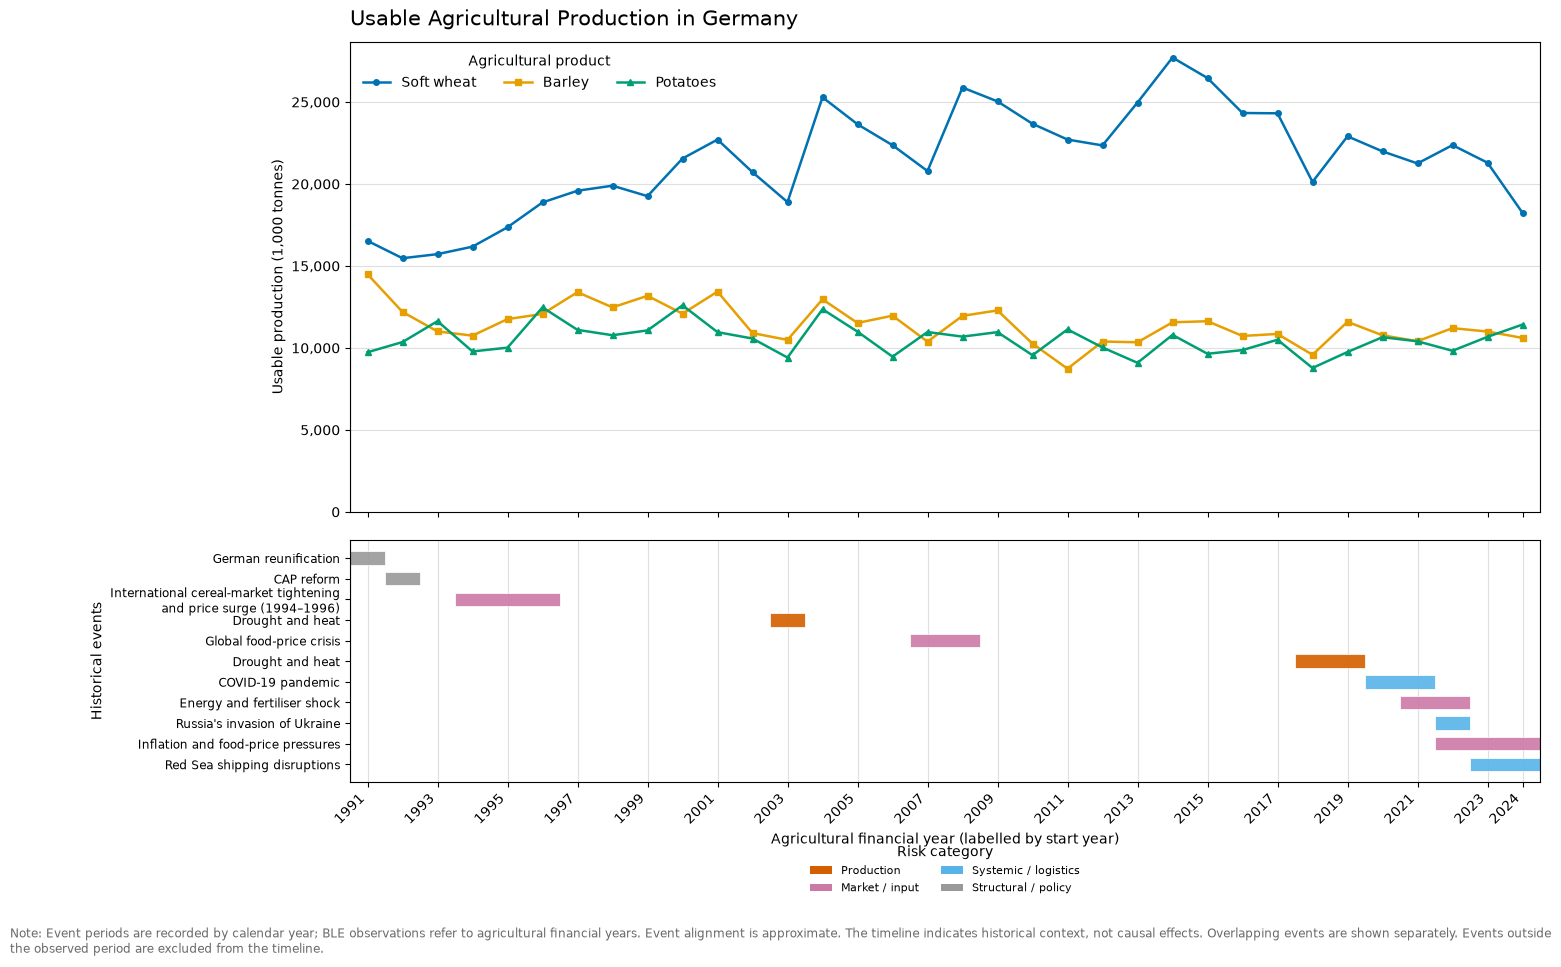

Events outside the observed period: Middle East conflict


In [10]:

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter

# ============================================================
# 1. PREPARE DATA
# ============================================================

production_plot = analytical_df[
    ["Wirtschaftsjahr", "Bilanz Produkt", "Verwendbare Erzeugung"]
].copy()

# Convert production values to numeric
production_plot["Verwendbare Erzeugung"] = pd.to_numeric(
    production_plot["Verwendbare Erzeugung"],
    errors="coerce"
)

# Extract the first calendar year from labels such as 1991/92
def get_start_year(value):
    match = re.search(r"(19|20)\d{2}", str(value))
    return int(match.group()) if match else np.nan

production_plot["Startjahr"] = (
    production_plot["Wirtschaftsjahr"].apply(get_start_year)
)

production_plot = production_plot.dropna(
    subset=["Startjahr", "Verwendbare Erzeugung"]
).copy()

production_plot["Startjahr"] = (
    production_plot["Startjahr"].astype(int)
)

# Map each financial year to its approximate midpoint.
# This is a plotting convention, not an exact observation date.
production_plot["Zeitpunkt"] = (
    production_plot["Startjahr"] + 0.5
)

# Check whether duplicate product-year observations exist
duplicates = production_plot.duplicated(
    subset=["Bilanz Produkt", "Startjahr"],
    keep=False
)

if duplicates.any():
    raise ValueError(
        "Duplicate product-year observations found. "
        "Check analytical_df before plotting."
    )

production_plot = production_plot.sort_values(
    ["Startjahr", "Bilanz Produkt"]
)

# Observed time interval
first_year = production_plot["Startjahr"].min()
last_year = production_plot["Startjahr"].max()

# ============================================================
# 2. PRODUCT STYLES
# ============================================================

product_styles = {
    "Weichweizen": {
        "label": "Soft wheat",
        "color": "#0072B2",
        "marker": "o",
    },
    "Gerste": {
        "label": "Barley",
        "color": "#E69F00",
        "marker": "s",
    },
    "Kartoffeln": {
        "label": "Potatoes",
        "color": "#009E73",
        "marker": "^",
    },
}

# ============================================================
# 3. HISTORICAL EVENTS
# ============================================================

historical_events = [
    {
        "start": 1990, "end": 1991,
        "label": "German reunification",
        "category": "Structural / policy",
    },
    {
        "start": 1992, "end": 1992,
        "label": "CAP reform",
        "category": "Structural / policy",
    },
    {
        "start": 1994, "end": 1996,
        "label": (
            "International cereal-market tightening\n"
            "and price surge (1994–1996)"
        ),
        "category": "Market / input",
    },
    {
        "start": 2003, "end": 2003,
        "label": "Drought and heat",
        "category": "Production",
    },
    {
        "start": 2007, "end": 2008,
        "label": "Global food-price crisis",
        "category": "Market / input",
    },
    {
        "start": 2018, "end": 2019,
        "label": "Drought and heat",
        "category": "Production",
    },
    {
        "start": 2020, "end": 2021,
        "label": "COVID-19 pandemic",
        "category": "Systemic / logistics",
    },
    {
        "start": 2021, "end": 2022,
        "label": "Energy and fertiliser shock",
        "category": "Market / input",
    },
    {
        "start": 2022, "end": 2022,
        "label": "Russia's invasion of Ukraine",
        "category": "Systemic / logistics",
    },
    {
        "start": 2022, "end": 2024,
        "label": "Inflation and food-price pressures",
        "category": "Market / input",
    },
    {
        "start": 2023, "end": 2024,
        "label": "Red Sea shipping disruptions",
        "category": "Systemic / logistics",
    },
    {
        "start": 2026, "end": 2026,
        "label": "Middle East conflict",
        "category": "Systemic / logistics",
    },
]

# Category colours are used only for event classification.
event_colors = {
    "Production": "#D55E00",
    "Market / input": "#CC79A7",
    "Systemic / logistics": "#56B4E9",
    "Structural / policy": "#999999",
}

# ============================================================
# 4. IDENTIFY OBSERVED AND OUT-OF-SAMPLE EVENTS
# ============================================================

# Calendar-year intervals are represented as [start, end + 1).
# The observed financial-year coverage is approximated by
# [first_year, last_year + 1).

observed_events = []
outside_events = []

for event in historical_events:
    event_start = event["start"]
    event_end_exclusive = event["end"] + 1

    # Keep only events overlapping the observed period
    if (
        event_end_exclusive > first_year
        and event_start < last_year + 1
    ):
        clipped_event = event.copy()
        clipped_event["plot_start"] = max(
            event_start, first_year
        )
        clipped_event["plot_end"] = min(
            event_end_exclusive, last_year + 1
        )
        observed_events.append(clipped_event)
    else:
        outside_events.append(event["label"])

# ============================================================
# 5. CREATE FIGURE: PRODUCTION + EVENT TIMELINE
# ============================================================

fig, (ax, ax_events) = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(17, 10),
    sharex=True,
    gridspec_kw={
        "height_ratios": [3.5, 1.8],
        "hspace": 0.08,
    }
)

# ------------------------------------------------------------
# Main panel: usable production
# ------------------------------------------------------------

for product, style in product_styles.items():

    product_data = production_plot[
        production_plot["Bilanz Produkt"] == product
    ].sort_values("Zeitpunkt")

    if product_data.empty:
        continue

    ax.plot(
        product_data["Zeitpunkt"],
        product_data["Verwendbare Erzeugung"],
        label=style["label"],
        color=style["color"],
        marker=style["marker"],
        linestyle="-",
        linewidth=1.8,
        markersize=4,
        zorder=3,
    )

ax.set_title(
    "Usable Agricultural Production in Germany",
    fontsize=15,
    pad=12,
    loc="left",
)

ax.set_ylabel("Usable production (1,000 tonnes)")
ax.yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

ax.set_ylim(bottom=0)
ax.grid(axis="y", color="grey", alpha=0.25)
ax.set_axisbelow(True)

ax.legend(
    title="Agricultural product",
    loc="upper left",
    frameon=False,
    ncol=3,
)

# ------------------------------------------------------------
# Lower panel: historical event timeline
# ------------------------------------------------------------

# One separate row per event preserves overlapping periods.
for row, event in enumerate(observed_events):

    start = event["plot_start"]
    end = event["plot_end"]

    ax_events.barh(
        y=row,
        width=end - start,
        left=start,
        height=0.65,
        color=event_colors[event["category"]],
        edgecolor="white",
        linewidth=0.6,
        alpha=0.9,
    )

ax_events.set_yticks(range(len(observed_events)))
ax_events.set_yticklabels(
    [event["label"] for event in observed_events],
    fontsize=8.5,
)

ax_events.invert_yaxis()
ax_events.set_ylabel("Historical events")
ax_events.set_xlabel(
    "Agricultural financial year (labelled by start year)"
)

ax_events.grid(axis="x", color="grey", alpha=0.25)
ax_events.set_axisbelow(True)

# ------------------------------------------------------------
# Shared x-axis and observation boundaries
# ------------------------------------------------------------

ax.set_xlim(first_year, last_year + 1)

# Label ticks at approximate financial-year midpoints.
tick_years = list(range(first_year, last_year + 1, 2))
if last_year not in tick_years:
    tick_years.append(last_year)

ax_events.set_xticks(
    [year + 0.5 for year in tick_years]
)
ax_events.set_xticklabels(
    [str(year) for year in tick_years],
    rotation=45,
    ha="right",
)

# Mark the boundaries of the observed period
for axis in (ax, ax_events):
    axis.axvline(
        first_year,
        color="black",
        linewidth=0.8,
        alpha=0.6,
    )
    axis.axvline(
        last_year + 1,
        color="black",
        linewidth=0.8,
        alpha=0.6,
    )

# ------------------------------------------------------------
# Event-category legend
# ------------------------------------------------------------

category_handles = [
    Patch(
        facecolor=color,
        label=category,
    )
    for category, color in event_colors.items()
]

ax_events.legend(
    handles=category_handles,
    title="Risk category",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=2,
    frameon=False,
    fontsize=8,
)

# ------------------------------------------------------------
# Methodological note
# ------------------------------------------------------------

note = (
    "Note: Event periods are recorded by calendar year; "
    "BLE observations refer to agricultural financial years. "
    "Event alignment is approximate. The timeline indicates "
    "historical context, not causal effects. Overlapping events "
    "are shown separately. Events outside the observed period "
    "are excluded from the timeline."
)

fig.text(
    0.08,
    0.015,
    note,
    ha="left",
    va="bottom",
    fontsize=8.5,
    color="dimgray",
    wrap=True,
)

# Keep space for labels, legends and the note
fig.subplots_adjust(
    left=0.28,
    right=0.98,
    top=0.93,
    bottom=0.19,
)

plt.show()

# Report events outside the sample
if outside_events:
    print(
        "Events outside the observed period:",
        ", ".join(outside_events),
    )


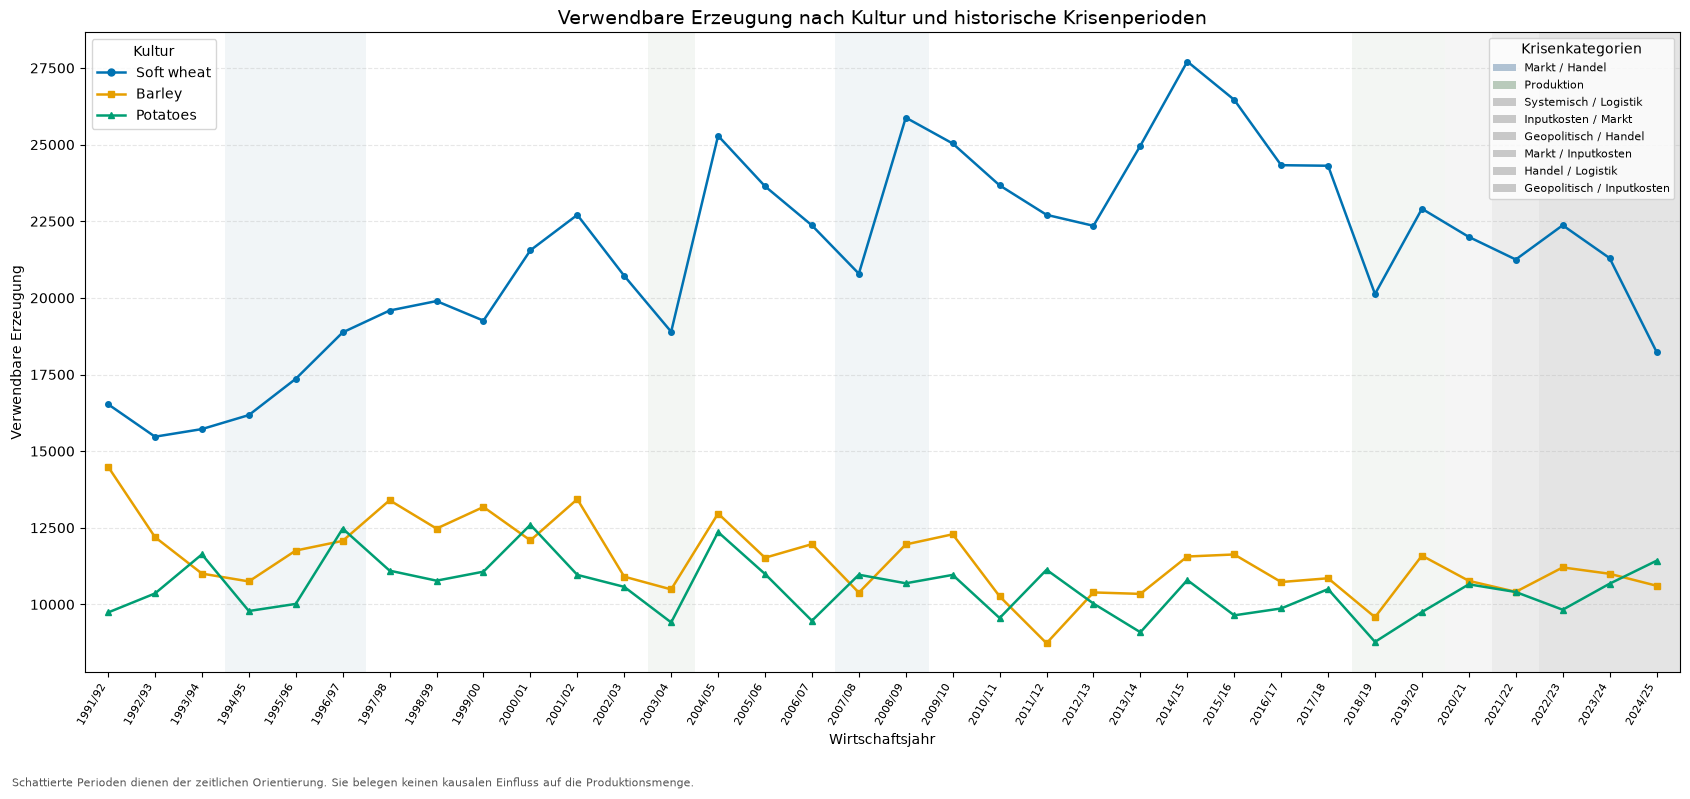

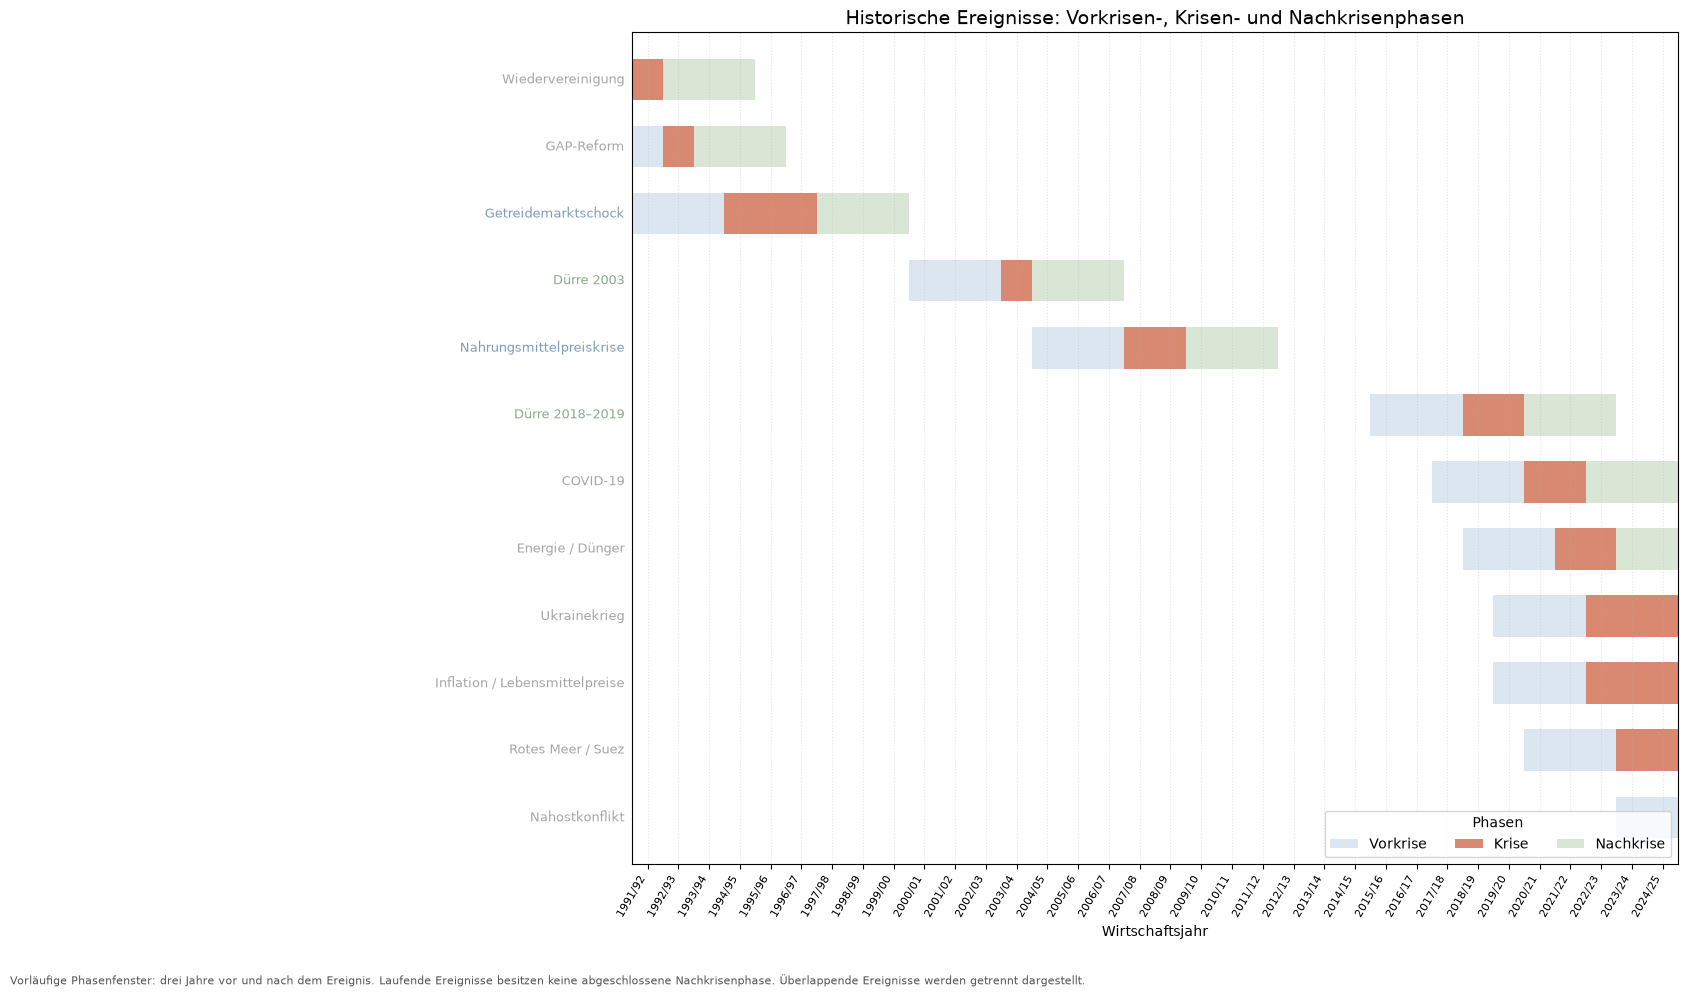

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ============================================================
# TIME RANGE
# ============================================================

first_year = int(production_plot["Startjahr"].min())
last_year = int(production_plot["Startjahr"].max())
plot_end_year = last_year + 1


# ============================================================
# COLOR PALETTE
# ============================================================

# Colors for event categories
event_colors = {
    "Produktion": "#8DAA91",
    "Markt/Preis": "#D9A441",
    "Markt / Preis": "#D9A441",
    "Markt / Handel": "#7F9DB9",
    "Handel/Lieferkette": "#7F9DB9",
    "Handel / Lieferkette": "#7F9DB9",
    "Inputkosten": "#C9826B",
    "Inputkosten / Energie": "#C9826B",
    "Finanziell": "#9B8BB5",
    "Politik/Institutionen": "#A6A6A6",
    "Politik / Institutionen": "#A6A6A6",
    "Geopolitisch/Systemisch": "#C17C8A",
    "Geopolitisch / Systemisch": "#C17C8A"
}

# Fallback color for categories not explicitly listed above
default_event_color = "#A6A6A6"


def get_event_color(event_type):
    return event_colors.get(event_type, default_event_color)


# Colors for the three phases
phase_styles = {
    "Vorkrise": {"color": "#DCE6F1"},
    "Krise": {"color": "#D98972"},
    "Nachkrise": {"color": "#D9E6D5"}
}


# ============================================================
# FIGURE 1: PRODUCTION VOLUME AND CRISIS PERIODS
# ============================================================

fig, ax = plt.subplots(figsize=(17, 8))

# Highlight only acute and ongoing shock periods.
# Structural events are not classified as acute crises.
for event in events:
    if event["kind"] not in ("shock", "ongoing"):
        continue

    start = max(event["start"], first_year)
    end = min(event["end"], last_year)

    if start > end:
        continue

    # Use subtle background shading without borders.
    ax.axvspan(
        start,
        end + 1,
        color=get_event_color(event["type"]),
        alpha=0.10,
        linewidth=0,
        zorder=0
    )

# Plot production lines
for product, style in product_styles.items():
    subset = production_plot[
        production_plot["Bilanz Produkt"] == product
    ].sort_values("Startjahr")

    if subset.empty:
        continue

    ax.plot(
        subset["Zeitpunkt"],
        subset["Verwendbare Erzeugung"],
        color=style["color"],
        marker=style["marker"],
        markersize=4,
        linewidth=1.8,
        label=style["label"],
        zorder=3
    )

# Create the legend for agricultural products
product_handles = [
    Line2D(
        [0], [0],
        color=style["color"],
        marker=style["marker"],
        linewidth=1.8,
        markersize=5,
        label=style["label"]
    )
    for style in product_styles.values()
]

product_legend = ax.legend(
    handles=product_handles,
    title="Kultur",
    loc="upper left",
    frameon=True
)

# Keep the product legend when adding the event-category legend
ax.add_artist(product_legend)

# Create a separate legend for event categories
categories_present = list(dict.fromkeys(
    event["type"]
    for event in events
    if event["kind"] in ("shock", "ongoing")
))

event_handles = [
    Patch(
        facecolor=get_event_color(category),
        edgecolor="none",
        alpha=0.6,
        label=category
    )
    for category in categories_present
]

ax.legend(
    handles=event_handles,
    title="Krisenkategorien",
    loc="upper right",
    fontsize=8,
    frameon=True
)

# Display all agricultural years
tick_years = np.arange(first_year, last_year + 1)

ax.set_xticks(tick_years + 0.5)
ax.set_xticklabels(
    [f"{y}/{str(y + 1)[-2:]}" for y in tick_years],
    rotation=60,
    ha="right",
    fontsize=8
)

ax.set_xlim(first_year, plot_end_year)
ax.set_xlabel("Wirtschaftsjahr")
ax.set_ylabel("Verwendbare Erzeugung")

ax.set_title(
    "Verwendbare Erzeugung nach Kultur und historische Krisenperioden",
    fontsize=14
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

fig.text(
    0.01, 0.01,
    "Schattierte Perioden dienen der zeitlichen Orientierung. "
    "Sie belegen keinen kausalen Einfluss auf die Produktionsmenge.",
    fontsize=8,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()


# ============================================================
# FIGURE 2: PRE-CRISIS, CRISIS, AND POST-CRISIS PHASES
# ============================================================

fig, ax = plt.subplots(figsize=(17, 10))

phase_order = ["Vorkrise", "Krise", "Nachkrise"]

for row, event in enumerate(events):
    y = len(events) - 1 - row

    # Pre-crisis phase: up to three years before the event
    pre_start = max(event["start"] - 3, first_year)
    pre_end = min(event["start"] - 1, last_year)

    if pre_start <= pre_end:
        ax.barh(
            y,
            pre_end + 1 - pre_start,
            left=pre_start,
            height=0.62,
            color=phase_styles["Vorkrise"]["color"],
            edgecolor="none",
            linewidth=0
        )

    # Crisis phase: the event's defined duration
    crisis_start = max(event["start"], first_year)
    crisis_end = min(event["end"], last_year)

    if crisis_start <= crisis_end:
        ax.barh(
            y,
            crisis_end + 1 - crisis_start,
            left=crisis_start,
            height=0.62,
            color=phase_styles["Krise"]["color"],
            edgecolor="none",
            linewidth=0
        )

    # Post-crisis phase: up to three years after completed events
    if event["kind"] != "ongoing":
        post_start = max(event["end"] + 1, first_year)
        post_end = min(event["end"] + 3, last_year)

        if post_start <= post_end:
            ax.barh(
                y,
                post_end + 1 - post_start,
                left=post_start,
                height=0.62,
                color=phase_styles["Nachkrise"]["color"],
                edgecolor="none",
                linewidth=0
            )

    # Display the event name to the left of the timeline
    ax.text(
        first_year - 0.25,
        y,
        event["name"],
        ha="right",
        va="center",
        fontsize=9,
        color=get_event_color(event["type"]),
        clip_on=False
    )

# Configure axes and labels
ax.set_yticks([])
ax.set_ylim(-0.7, len(events) - 0.3)
ax.set_xlim(first_year, plot_end_year)

tick_years = np.arange(first_year, last_year + 1)

ax.set_xticks(tick_years + 0.5)
ax.set_xticklabels(
    [f"{y}/{str(y + 1)[-2:]}" for y in tick_years],
    rotation=60,
    ha="right",
    fontsize=8
)

ax.set_xlabel("Wirtschaftsjahr")

ax.set_title(
    "Historische Ereignisse: Vorkrisen-, Krisen- und Nachkrisenphasen",
    fontsize=14
)

ax.grid(
    axis="x",
    linestyle=":",
    alpha=0.35
)

# Create a borderless legend for the three phases
phase_handles = [
    Patch(
        facecolor=phase_styles[phase]["color"],
        edgecolor="none",
        label=phase
    )
    for phase in phase_order
]

ax.legend(
    handles=phase_handles,
    title="Phasen",
    loc="lower right",
    ncol=3,
    frameon=True
)

fig.text(
    0.01, 0.01,
    "Vorläufige Phasenfenster: drei Jahre vor und nach dem Ereignis. "
    "Laufende Ereignisse besitzen keine abgeschlossene Nachkrisenphase. "
    "Überlappende Ereignisse werden getrennt dargestellt.",
    fontsize=8,
    color="#555555"
)

plt.tight_layout(rect=[0.25, 0.04, 1, 1])
plt.show()

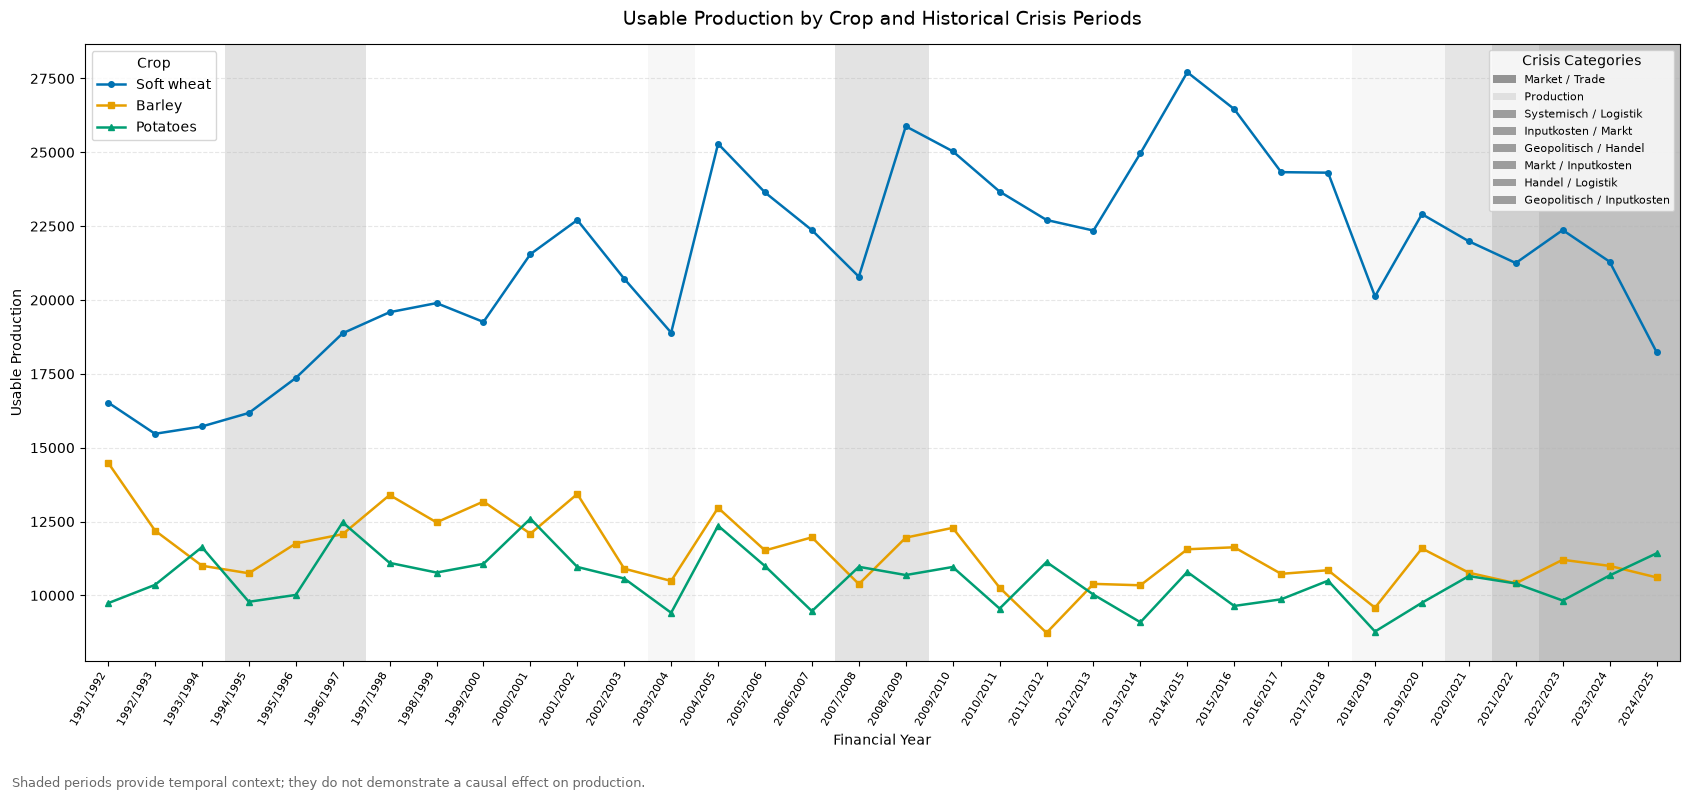

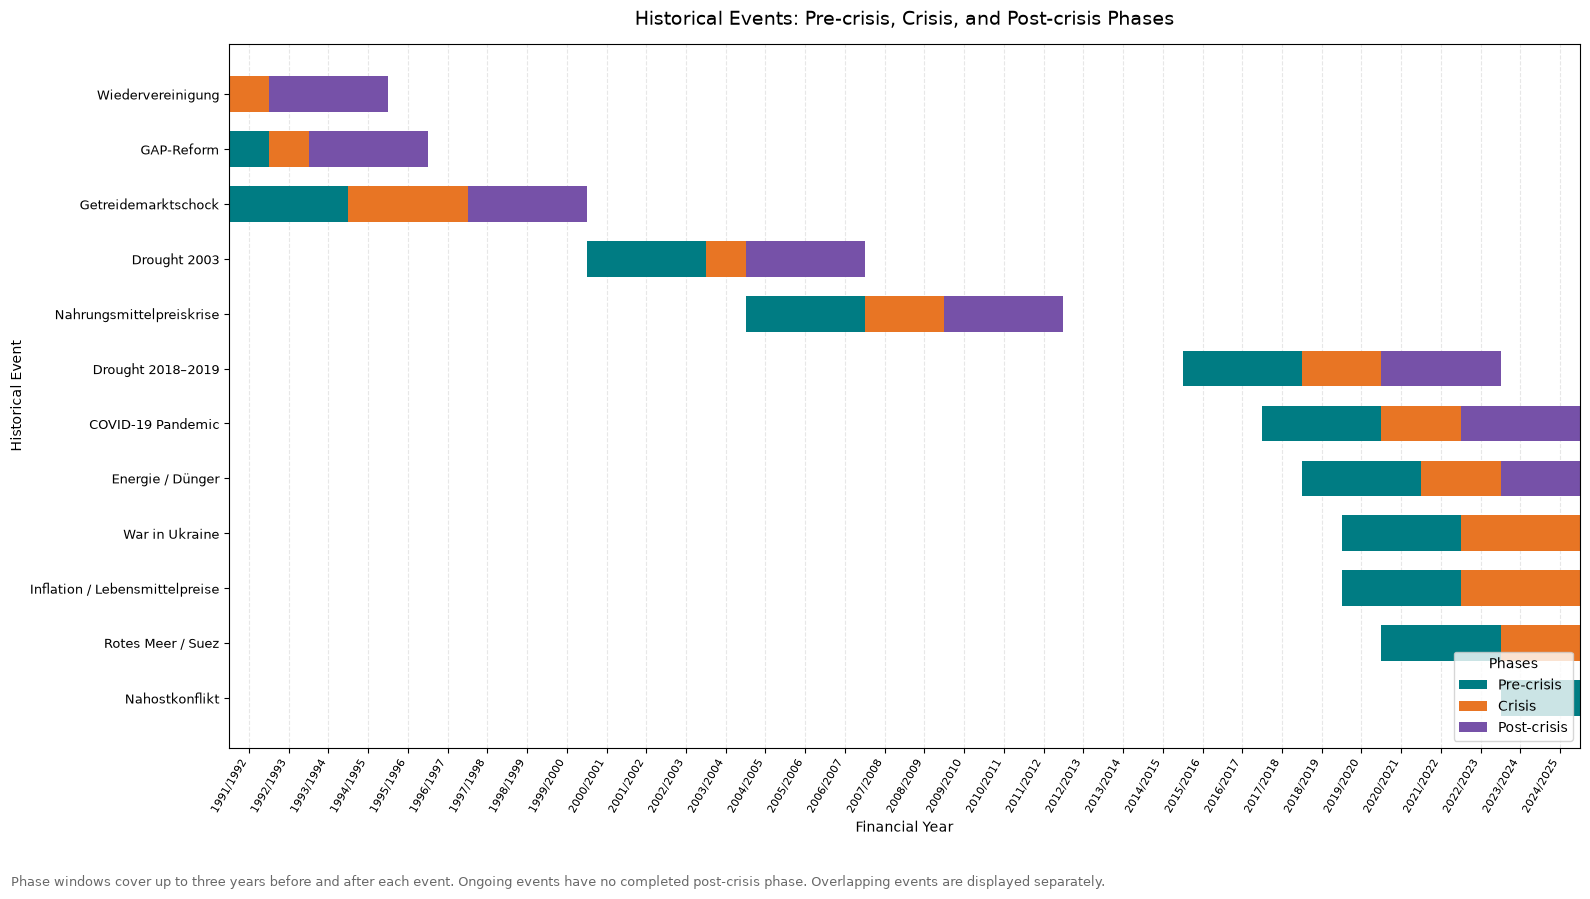

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ============================================================
# 1. TIME RANGE
# ============================================================

first_year = int(production_plot["Startjahr"].min())
last_year = int(production_plot["Startjahr"].max())
plot_end_year = last_year + 1

tick_years = np.arange(first_year, last_year + 1)

# Full marketing-year labels, e.g. 1991/1992
marketing_year_labels = [
    f"{year}/{year + 1}" for year in tick_years
]


# ============================================================
# 2. COLOR SETTINGS
# ============================================================

event_colors = {
    "Produktion": "#D9D9D9",
    "Markt/Preis": "#A6A6A6",
    "Markt / Preis": "#A6A6A6",
    "Markt / Handel": "#737373",
    "Handel/Lieferkette": "#737373",
    "Handel / Lieferkette": "#737373",
    "Inputkosten": "#BFBFBF",
    "Inputkosten / Energie": "#BFBFBF",
    "Finanziell": "#8C8C8C",
    "Politik/Institutionen": "#595959",
    "Politik / Institutionen": "#595959",
    "Geopolitisch/Systemisch": "#404040",
    "Geopolitisch / Systemisch": "#404040",
}

default_event_color = "#808080"


def get_event_color(event_type):
    return event_colors.get(event_type, default_event_color)


phase_styles = {
    "Pre-crisis": {"color": "#007C83"},
    "Crisis": {"color": "#E87524"},
    "Post-crisis": {"color": "#7651A8"},
}

phase_order = ["Pre-crisis", "Crisis", "Post-crisis"]


# ============================================================
# 3. ENGLISH CATEGORY LABELS
# ============================================================

category_labels = {
    "Produktion": "Production",
    "Markt/Preis": "Market / Prices",
    "Markt / Preis": "Market / Prices",
    "Markt / Handel": "Market / Trade",
    "Handel/Lieferkette": "Trade / Supply Chain",
    "Handel / Lieferkette": "Trade / Supply Chain",
    "Inputkosten": "Input Costs",
    "Inputkosten / Energie": "Input Costs / Energy",
    "Finanziell": "Financial",
    "Politik/Institutionen": "Policy / Institutions",
    "Politik / Institutionen": "Policy / Institutions",
    "Geopolitisch/Systemisch": "Geopolitical / Systemic",
    "Geopolitisch / Systemisch": "Geopolitical / Systemic",
}


# ============================================================
# 4. ENGLISH EVENT NAMES
# ============================================================

event_name_translations = {
    "Finanzkrise": "Global Financial Crisis",
    "Finanzkrise 2008": "Global Financial Crisis (2008)",
    "Globale Finanzkrise": "Global Financial Crisis",
    "Weltfinanzkrise": "Global Financial Crisis",
    "Eurokrise": "Eurozone Crisis",
    "Staatsschuldenkrise": "European Sovereign Debt Crisis",
    "COVID-19-Pandemie": "COVID-19 Pandemic",
    "Corona-Pandemie": "COVID-19 Pandemic",
    "COVID-19": "COVID-19 Pandemic",
    "Pandemie": "Energy Crisis",
    "Energiekrise": "Energy Crisis",
    "Dürre": "Drought",
    "Dürreperioden": "Drought Periods",
    "Hitzewelle": "Heatwave",
    "Klimawandel": "Climate Change",
    "Wirtschaftskrise": "Economic Crisis",
    "Ölkrise": "Oil Crisis",
    "Ölpreiskrise": "Oil Price Crisis",
    "Russischer Angriff auf die Ukraine": "Russian Invasion of Ukraine",
    "Ukrainekrieg": "War in Ukraine",
    "Krieg in der Ukraine": "War in Ukraine",
    "Brexit": "Brexit",
    "Finanz- und Wirtschaftskrise": "Financial and Economic Crisis",
}


def translate_event_name(name):
    if name is None:
        return "Unnamed event"

    name = str(name).strip()

    if name in event_name_translations:
        return event_name_translations[name]

    fallback_translations = {
        "Finanzkrise": "Financial Crisis",
        "Wirtschaftskrise": "Economic Crisis",
        "Energiekrise": "Energy Crisis",
        "Dürre": "Drought",
        "Hitzewelle": "Heatwave",
        "Pandemie": "Pandemic",
        "Ukrainekrieg": "War in Ukraine",
        "Staatsschuldenkrise": "Sovereign Debt Crisis",
        "Ölkrise": "Oil Crisis",
        "Klimawandel": "Climate Change",
    }

    for german, english in fallback_translations.items():
        if german.lower() in name.lower():
            return name.replace(german, english)

    return name


# ============================================================
# FIGURE 1: PRODUCTION AND HISTORICAL CRISIS PERIODS
# ============================================================

fig, ax = plt.subplots(figsize=(17, 8))

# Shade acute and ongoing shock periods
for event in events:
    if event.get("kind") not in ("shock", "ongoing"):
        continue

    start = max(int(event["start"]), first_year)
    end = min(int(event["end"]), last_year)

    if start > end:
        continue

    ax.axvspan(
        start,
        end + 1,
        color=get_event_color(event.get("type", "Other")),
        alpha=0.20,
        linewidth=0,
        zorder=0,
    )


# Plot production lines.
# The +0.5 shift aligns every point with its marketing-year tick.
for product, style in product_styles.items():
    subset = production_plot[
        production_plot["Bilanz Produkt"] == product
    ].copy()

    subset = subset.dropna(
        subset=["Startjahr", "Verwendbare Erzeugung"]
    ).sort_values("Startjahr")

    if subset.empty:
        continue

    ax.plot(
        subset["Startjahr"].astype(float) + 0.5,
        subset["Verwendbare Erzeugung"],
        color=style.get("color"),
        marker=style.get("marker", "o"),
        markersize=style.get("markersize", 4),
        linewidth=style.get("linewidth", 1.8),
        linestyle=style.get("linestyle", "-"),
        label=style.get("label", product),
        zorder=3,
    )


# Crop legend
crop_legend = ax.legend(
    title="Crop",
    loc="upper left",
    frameon=True,
)
ax.add_artist(crop_legend)


# Crisis-category legend
categories_present = list(dict.fromkeys(
    event.get("type", "Other")
    for event in events
    if event.get("kind") in ("shock", "ongoing")
))

category_handles = [
    mpatches.Patch(
        facecolor=get_event_color(category),
        edgecolor="none",
        alpha=0.75,
        label=category_labels.get(category, category),
    )
    for category in categories_present
]

if category_handles:
    ax.legend(
        handles=category_handles,
        title="Crisis Categories",
        loc="upper right",
        fontsize=8,
        frameon=True,
    )


# Marketing-year axis
ax.set_xticks(tick_years + 0.5)
ax.set_xticklabels(
    marketing_year_labels,
    rotation=60,
    ha="right",
    fontsize=8,
)

ax.set_xlim(first_year, plot_end_year)

ax.set_xlabel("Financial Year")
ax.set_ylabel("Usable Production")

ax.set_title(
    "Usable Production by Crop and Historical Crisis Periods",
    fontsize=14,
    pad=14,
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3,
    zorder=1,
)

fig.text(
    0.01,
    0.01,
    "Shaded periods provide temporal context; "
    "they do not demonstrate a causal effect on production.",
    fontsize=9,
    color="dimgray",
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()


# ============================================================
# FIGURE 2: PRE-CRISIS, CRISIS, AND POST-CRISIS PHASES
# ============================================================

fig, ax = plt.subplots(figsize=(16, 9))

phase_handles = [
    mpatches.Patch(
        facecolor=phase_styles[phase]["color"],
        edgecolor="none",
        label=phase,
    )
    for phase in phase_order
]

y_positions = list(range(len(events)))

for y, event in zip(y_positions, events):
    start_year = int(event["start"])
    end_year = int(event["end"])

    # Pre-crisis phase: up to three years before the event
    pre_start = max(start_year - 3, first_year)
    pre_end = min(start_year - 1, last_year)

    if pre_start <= pre_end:
        ax.barh(
            y,
            width=pre_end - pre_start + 1,
            left=pre_start,
            height=0.65,
            color=phase_styles["Pre-crisis"]["color"],
            edgecolor="none",
        )

    # Crisis phase
    crisis_start = max(start_year, first_year)
    crisis_end = min(end_year, last_year)

    if crisis_start <= crisis_end:
        ax.barh(
            y,
            width=crisis_end - crisis_start + 1,
            left=crisis_start,
            height=0.65,
            color=phase_styles["Crisis"]["color"],
            edgecolor="none",
        )

    # Post-crisis phase only for completed events
    if event.get("kind") != "ongoing":
        post_start = max(end_year + 1, first_year)
        post_end = min(end_year + 3, last_year)

        if post_start <= post_end:
            ax.barh(
                y,
                width=post_end - post_start + 1,
                left=post_start,
                height=0.65,
                color=phase_styles["Post-crisis"]["color"],
                edgecolor="none",
            )


# English event names
event_labels = [
    translate_event_name(event.get("name", "Unnamed event"))
    for event in events
]

ax.set_yticks(y_positions)
ax.set_yticklabels(event_labels, fontsize=9)
ax.invert_yaxis()


# Same marketing-year axis as Figure 1
ax.set_xticks(tick_years + 0.5)
ax.set_xticklabels(
    marketing_year_labels,
    rotation=60,
    ha="right",
    fontsize=8,
)

ax.set_xlim(first_year, plot_end_year)

ax.set_title(
    "Historical Events: Pre-crisis, Crisis, and Post-crisis Phases",
    fontsize=14,
    pad=14,
)

ax.set_xlabel("Financial Year")
ax.set_ylabel("Historical Event")

ax.legend(
    handles=phase_handles,
    title="Phases",
    loc="lower right",
    frameon=True,
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3,
)

ax.set_axisbelow(True)

fig.text(
    0.01,
    0.01,
    "Phase windows cover up to three years before and after each event. "
    "Ongoing events have no completed post-crisis phase. "
    "Overlapping events are displayed separately.",
    fontsize=9,
    color="dimgray",
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

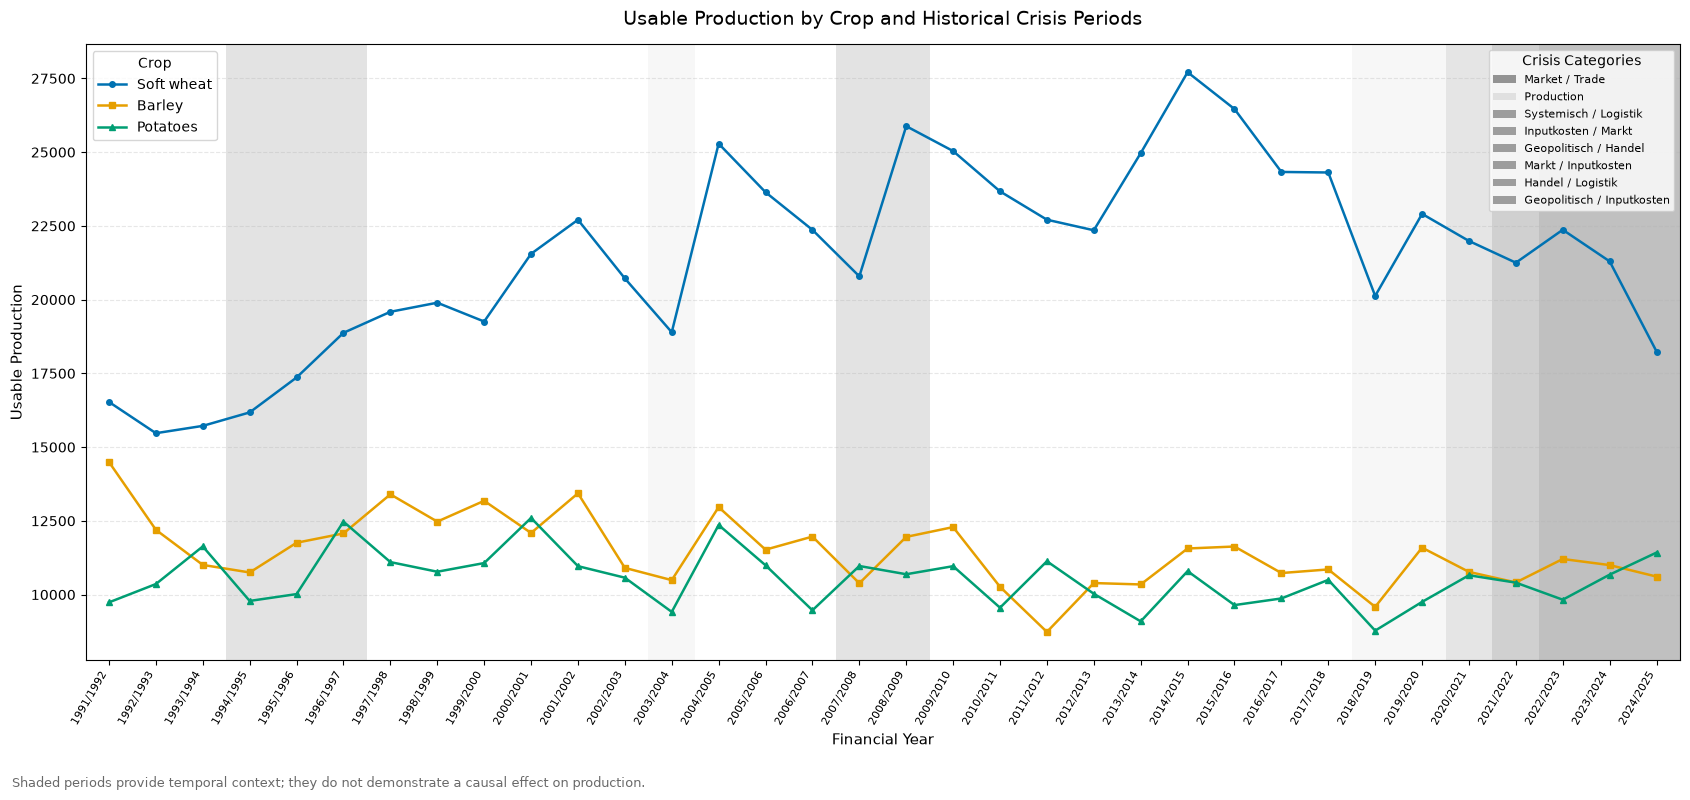

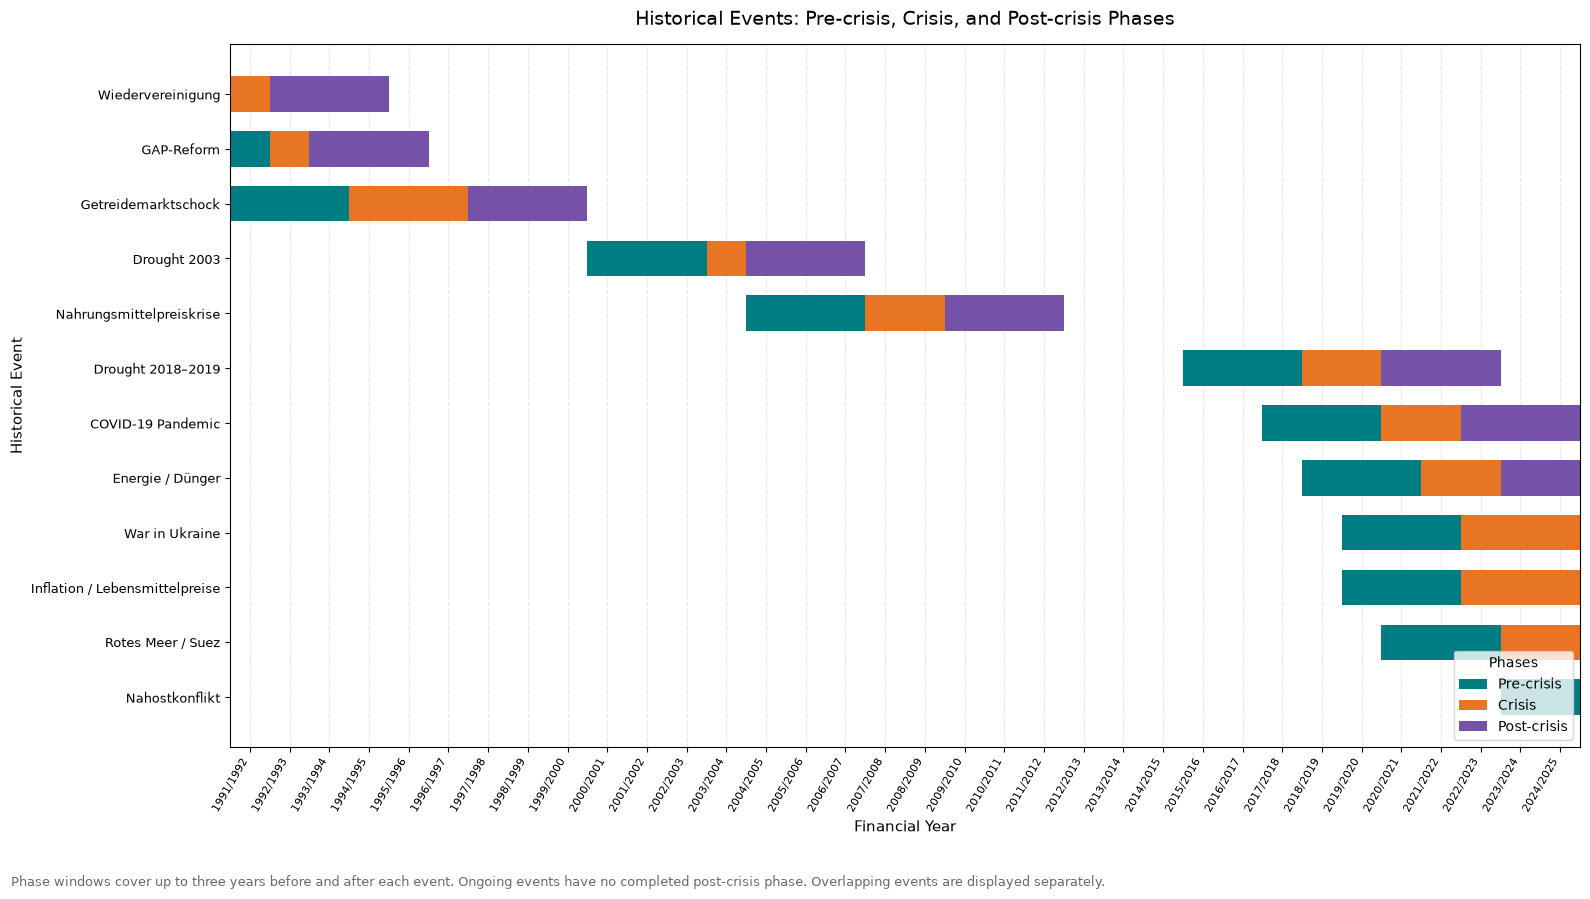

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ============================================================
# 1. TIME RANGE AND MARKETING-YEAR LABELS
# ============================================================

first_year = int(production_plot["Startjahr"].min())
last_year = int(production_plot["Startjahr"].max())
plot_end_year = last_year + 1

tick_years = np.arange(first_year, last_year + 1)

# Full marketing-year labels, e.g. 1991/1992
marketing_year_labels = [
    f"{year}/{year + 1}" for year in tick_years
]


# ============================================================
# 2. COLOR SETTINGS
# ============================================================

event_colors = {
    "Produktion": "#D9D9D9",
    "Markt/Preis": "#A6A6A6",
    "Markt / Preis": "#A6A6A6",
    "Markt / Handel": "#737373",
    "Handel/Lieferkette": "#737373",
    "Handel / Lieferkette": "#737373",
    "Inputkosten": "#BFBFBF",
    "Inputkosten / Energie": "#BFBFBF",
    "Finanziell": "#8C8C8C",
    "Politik/Institutionen": "#595959",
    "Politik / Institutionen": "#595959",
    "Geopolitisch/Systemisch": "#404040",
    "Geopolitisch / Systemisch": "#404040",
}

default_event_color = "#808080"


def get_event_color(event_type):
    return event_colors.get(event_type, default_event_color)


phase_styles = {
    "Pre-crisis": {"color": "#007C83"},
    "Crisis": {"color": "#E87524"},
    "Post-crisis": {"color": "#7651A8"},
}

phase_order = ["Pre-crisis", "Crisis", "Post-crisis"]


# ============================================================
# 3. ENGLISH CATEGORY LABELS
# ============================================================

category_labels = {
    "Produktion": "Production",
    "Markt/Preis": "Market / Prices",
    "Markt / Preis": "Market / Prices",
    "Markt / Handel": "Market / Trade",
    "Handel/Lieferkette": "Trade / Supply Chain",
    "Handel / Lieferkette": "Trade / Supply Chain",
    "Inputkosten": "Input Costs",
    "Inputkosten / Energie": "Input Costs / Energy",
    "Finanziell": "Financial",
    "Politik/Institutionen": "Policy / Institutions",
    "Politik / Institutionen": "Policy / Institutions",
    "Geopolitisch/Systemisch": "Geopolitical / Systemic",
    "Geopolitisch / Systemisch": "Geopolitical / Systemic",
}


# ============================================================
# 4. ENGLISH EVENT NAMES
# ============================================================

event_name_translations = {
    "Finanzkrise": "Global Financial Crisis",
    "Finanzkrise 2008": "Global Financial Crisis (2008)",
    "Globale Finanzkrise": "Global Financial Crisis",
    "Weltfinanzkrise": "Global Financial Crisis",
    "Eurokrise": "Eurozone Crisis",
    "Staatsschuldenkrise": "European Sovereign Debt Crisis",
    "COVID-19-Pandemie": "COVID-19 Pandemic",
    "Corona-Pandemie": "COVID-19 Pandemic",
    "COVID-19": "COVID-19 Pandemic",
    "Pandemie": "Pandemic",
    "Energiekrise": "Energy Crisis",
    "Dürre": "Drought",
    "Dürreperioden": "Drought Periods",
    "Hitzewelle": "Heatwave",
    "Klimawandel": "Climate Change",
    "Wirtschaftskrise": "Economic Crisis",
    "Ölkrise": "Oil Crisis",
    "Ölpreiskrise": "Oil Price Crisis",
    "Russischer Angriff auf die Ukraine": "Russian Invasion of Ukraine",
    "Ukrainekrieg": "War in Ukraine",
    "Krieg in der Ukraine": "War in Ukraine",
    "Brexit": "Brexit",
    "Finanz- und Wirtschaftskrise": "Financial and Economic Crisis",
}


def translate_event_name(name):
    if name is None:
        return "Unnamed event"

    name = str(name).strip()

    if name in event_name_translations:
        return event_name_translations[name]

    # Fallback for event names containing known German phrases
    fallback_translations = {
        "Finanzkrise": "Financial Crisis",
        "Wirtschaftskrise": "Economic Crisis",
        "Energiekrise": "Energy Crisis",
        "Dürre": "Drought",
        "Hitzewelle": "Heatwave",
        "Pandemie": "Pandemic",
        "Ukrainekrieg": "War in Ukraine",
        "Staatsschuldenkrise": "Sovereign Debt Crisis",
        "Ölkrise": "Oil Crisis",
        "Klimawandel": "Climate Change",
    }

    for german, english in fallback_translations.items():
        if german.lower() in name.lower():
            return name.replace(german, english)

    # Preserve names for which no reliable translation is available
    return name


# ============================================================
# FIGURE 1: PRODUCTION AND HISTORICAL CRISIS PERIODS
# ============================================================

fig, ax = plt.subplots(figsize=(17, 8))

# Shade acute and ongoing shock periods
for event in events:
    if event.get("kind") not in ("shock", "ongoing"):
        continue

    start = max(int(event["start"]), first_year)
    end = min(int(event["end"]), last_year)

    if start > end:
        continue

    ax.axvspan(
        start,
        end + 1,
        color=get_event_color(event.get("type", "Other")),
        alpha=0.20,
        linewidth=0,
        zorder=0,
    )


# Plot production lines.
# IMPORTANT:
# Data points are shifted by 0.5 so that they align exactly
# with the marketing-year tick marks.
for product, style in product_styles.items():

    subset = production_plot[
        production_plot["Bilanz Produkt"] == product
    ].copy()

    subset = subset.dropna(
        subset=["Startjahr", "Verwendbare Erzeugung"]
    )

    subset = subset.sort_values("Startjahr")

    if subset.empty:
        continue

    ax.plot(
        subset["Startjahr"].astype(float) + 0.5,
        subset["Verwendbare Erzeugung"],
        color=style.get("color"),
        marker=style.get("marker", "o"),
        markersize=4,
        linewidth=style.get("linewidth", 1.8),
        linestyle=style.get("linestyle", "-"),
        label=style.get("label", product),
        zorder=3,
    )


# Crop legend
crop_legend = ax.legend(
    title="Crop",
    loc="upper left",
    frameon=True,
)

ax.add_artist(crop_legend)


# Crisis-category legend
categories_present = list(dict.fromkeys(
    event.get("type", "Other")
    for event in events
    if event.get("kind") in ("shock", "ongoing")
))

category_handles = [
    mpatches.Patch(
        facecolor=get_event_color(category),
        edgecolor="none",
        alpha=0.75,
        label=category_labels.get(category, category),
    )
    for category in categories_present
]

if category_handles:
    ax.legend(
        handles=category_handles,
        title="Crisis Categories",
        loc="upper right",
        fontsize=8,
        frameon=True,
    )


# Marketing-year ticks are centred in each yearly interval
ax.set_xticks(tick_years + 0.5)

ax.set_xticklabels(
    marketing_year_labels,
    rotation=60,
    ha="right",
    fontsize=8,
)

ax.set_xlim(first_year, plot_end_year)

ax.set_xlabel("Financial Year", fontsize=11)
ax.set_ylabel("Usable Production", fontsize=11)

ax.set_title(
    "Usable Production by Crop and Historical Crisis Periods",
    fontsize=14,
    pad=14,
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3,
    zorder=1,
)

fig.text(
    0.01,
    0.01,
    "Shaded periods provide temporal context; "
    "they do not demonstrate a causal effect on production.",
    fontsize=9,
    color="dimgray",
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()


# ============================================================
# FIGURE 2: PRE-CRISIS, CRISIS, AND POST-CRISIS PHASES
# ============================================================

fig, ax = plt.subplots(figsize=(16, 9))

# Legend for the three phases
phase_handles = [
    mpatches.Patch(
        facecolor=phase_styles[phase]["color"],
        edgecolor="none",
        label=phase,
    )
    for phase in phase_order
]


# One horizontal row per historical event
y_positions = list(range(len(events)))

for y, event in zip(y_positions, events):

    start_year = int(event["start"])
    end_year = int(event["end"])

    # Pre-crisis phase: up to three years before the event
    pre_start = max(start_year - 3, first_year)
    pre_end = min(start_year - 1, last_year)

    if pre_start <= pre_end:
        ax.barh(
            y,
            width=pre_end - pre_start + 1,
            left=pre_start,
            height=0.65,
            color=phase_styles["Pre-crisis"]["color"],
            edgecolor="none",
        )

    # Crisis phase
    crisis_start = max(start_year, first_year)
    crisis_end = min(end_year, last_year)

    if crisis_start <= crisis_end:
        ax.barh(
            y,
            width=crisis_end - crisis_start + 1,
            left=crisis_start,
            height=0.65,
            color=phase_styles["Crisis"]["color"],
            edgecolor="none",
        )

    # Post-crisis phase only for completed events
    if event.get("kind") != "ongoing":

        post_start = max(end_year + 1, first_year)
        post_end = min(end_year + 3, last_year)

        if post_start <= post_end:
            ax.barh(
                y,
                width=post_end - post_start + 1,
                left=post_start,
                height=0.65,
                color=phase_styles["Post-crisis"]["color"],
                edgecolor="none",
            )


# Translate event names for display
event_labels = [
    translate_event_name(event.get("name", "Unnamed event"))
    for event in events
]

ax.set_yticks(y_positions)
ax.set_yticklabels(event_labels, fontsize=9)
ax.invert_yaxis()


# Use the same marketing-year axis as Figure 1
ax.set_xticks(tick_years + 0.5)

ax.set_xticklabels(
    marketing_year_labels,
    rotation=60,
    ha="right",
    fontsize=8,
)

ax.set_xlim(first_year, plot_end_year)

ax.set_title(
    "Historical Events: Pre-crisis, Crisis, and Post-crisis Phases",
    fontsize=14,
    pad=14,
)

ax.set_xlabel("Financial Year", fontsize=11)
ax.set_ylabel("Historical Event", fontsize=11)

ax.legend(
    handles=phase_handles,
    title="Phases",
    loc="lower right",
    frameon=True,
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3,
)

ax.set_axisbelow(True)

fig.text(
    0.01,
    0.01,
    "Phase windows cover up to three years before and after each event. "
    "Ongoing events have no completed post-crisis phase. "
    "Overlapping events are displayed separately.",
    fontsize=9,
    color="dimgray",
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

In [29]:
# Inspect the analytical dataset

print("Dataset shape:", analytical_df.shape)

print("\nColumns:")
print(analytical_df.columns.tolist())

print("\nProducts:")
print(analytical_df["Bilanz Produkt"].unique())

print("\nFinancial years:")
print(
    analytical_df["Wirtschaftsjahr"]
    .drop_duplicates()
    .sort_values()
    .tolist()
)

print("\nHistorical events:")
print(events)

Dataset shape: (102, 12)

Columns:
['Wirtschaftsjahr', 'Bilanz Produkt', 'Ausfuhr', 'Einfuhr', 'Selbstversorgungsgrad in %', 'Verwendbare Erzeugung', 'Inlandsverwendung standardisiert', 'Nettohandelsbilanz', 'Erzeugungsänderung in %', 'Inlandsverwendungsänderung in %', 'Exportquote in %', 'Importquote in %']

Products:
<StringArray>
['Gerste', 'Kartoffeln', 'Weichweizen']
Length: 3, dtype: str

Financial years:
['1991/92', '1992/93', '1993/94', '1994/95', '1995/96', '1996/97', '1997/98', '1998/99', '1999/00', '2000/01', '2001/02', '2002/03', '2003/04', '2004/05', '2005/06', '2006/07', '2007/08', '2008/09', '2009/10', '2010/11', '2011/12', '2012/13', '2013/14', '2014/15', '2015/16', '2016/17', '2017/18', '2018/19', '2019/20', '2020/21', '2021/22', '2022/23', '2023/24', '2024/25']

Historical events:
[{'name': 'Wiedervereinigung', 'start': 1990, 'end': 1991, 'type': 'Strukturell / institutionell', 'kind': 'context', 'pre_start': 1987, 'pre_end': 1989, 'crisis_start': 1990, 'crisis_end': 

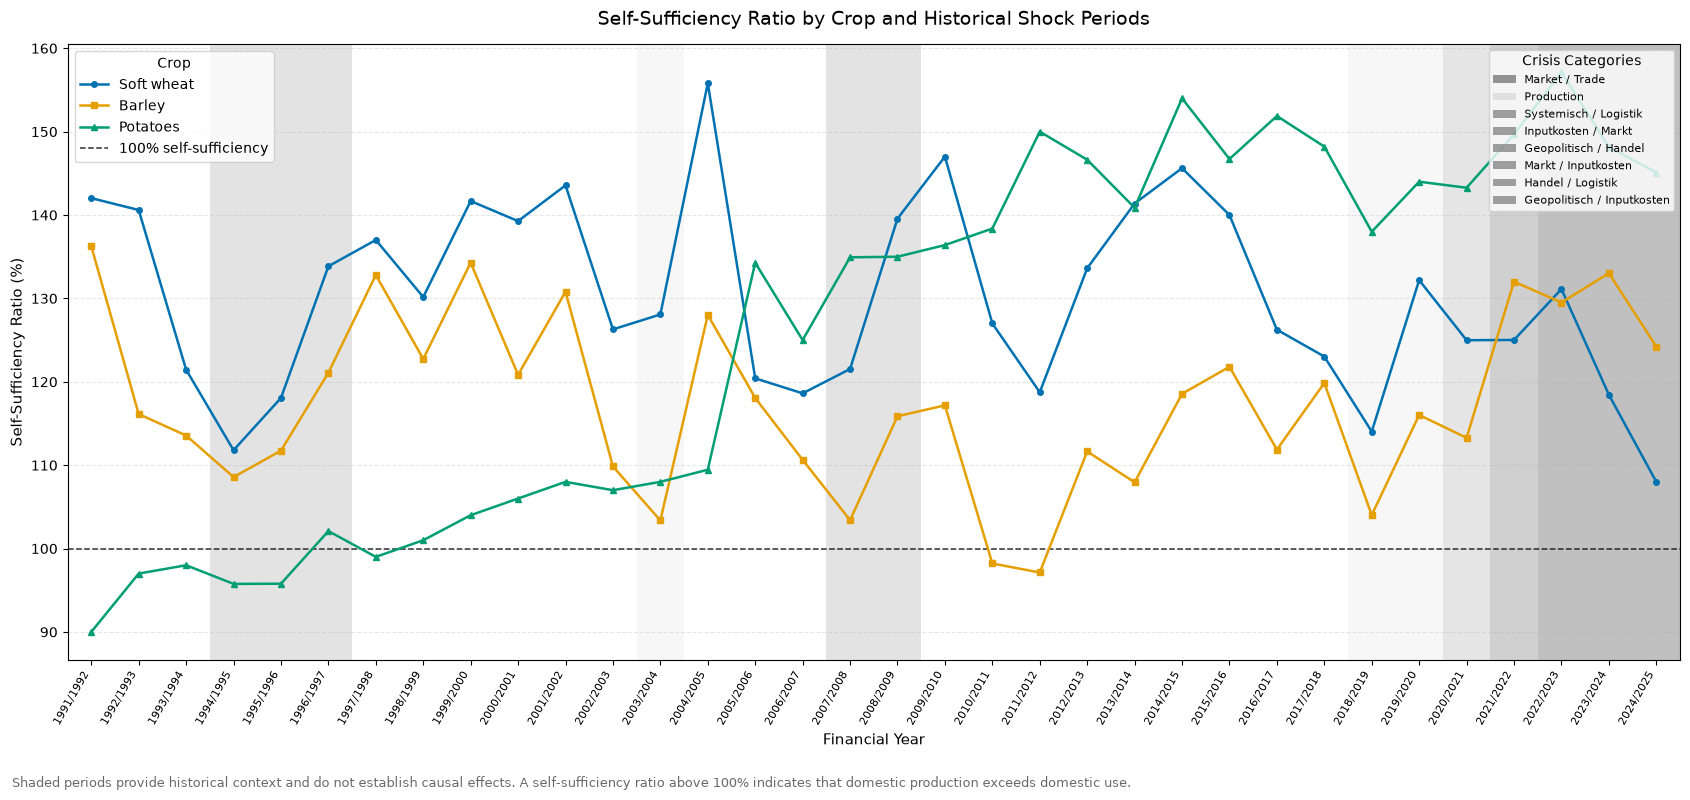

In [34]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ============================================================
# 1. PREPARE THE DATA
# ============================================================

# Create a copy of the original analytical dataset
self_sufficiency_plot = analytical_df.copy()

# Extract the starting calendar year from the financial-year label
self_sufficiency_plot["Startjahr"] = (
    self_sufficiency_plot["Wirtschaftsjahr"]
    .str.split("/")
    .str[0]
    .astype(int)
)

# Sort observations chronologically by product
self_sufficiency_plot = self_sufficiency_plot.sort_values(
    ["Bilanz Produkt", "Startjahr"]
)

# Define the observed time range
first_year = int(self_sufficiency_plot["Startjahr"].min())
last_year = int(self_sufficiency_plot["Startjahr"].max())
plot_end_year = last_year + 1

tick_years = np.arange(first_year, last_year + 1)

# Use the same financial-year labels as in the production figure
marketing_year_labels = [
    f"{year}/{year + 1}" for year in tick_years
]


# ============================================================
# 2. DEFINE PRODUCT STYLES
# ============================================================

# Reuse the product_styles dictionary from the production plot
# if it already exists. Otherwise, define consistent defaults.

if "product_styles" not in globals():
    product_styles = {
        "Gerste": {
            "color": "#2878A5",
            "marker": "s",
            "markersize": 4,
            "linewidth": 1.8,
            "linestyle": "-",
            "label": "Barley",
        },
        "Kartoffeln": {
            "color": "#398564",
            "marker": "^",
            "markersize": 4,
            "linewidth": 1.8,
            "linestyle": "-",
            "label": "Potatoes",
        },
        "Weichweizen": {
            "color": "#D97732",
            "marker": "o",
            "markersize": 4,
            "linewidth": 1.8,
            "linestyle": "-",
            "label": "Soft Wheat",
        },
    }


# ============================================================
# 3. DEFINE HISTORICAL EVENT COLORS
# ============================================================

# Use the same event colors as in the original production figure

event_colors = {
    "Produktion": "#D9D9D9",
    "Markt/Preis": "#A6A6A6",
    "Markt / Preis": "#A6A6A6",
    "Markt / Handel": "#737373",
    "Handel/Lieferkette": "#737373",
    "Handel / Lieferkette": "#737373",
    "Inputkosten": "#BFBFBF",
    "Inputkosten / Energie": "#BFBFBF",
    "Finanziell": "#8C8C8C",
    "Politik/Institutionen": "#595959",
    "Politik / Institutionen": "#595959",
    "Geopolitisch/Systemisch": "#404040",
    "Geopolitisch / Systemisch": "#404040",
}

default_event_color = "#808080"


def get_event_color(event_type):
    return event_colors.get(event_type, default_event_color)


# Translate event categories into English
category_labels = {
    "Produktion": "Production",
    "Markt/Preis": "Market / Prices",
    "Markt / Preis": "Market / Prices",
    "Markt / Handel": "Market / Trade",
    "Handel/Lieferkette": "Trade / Supply Chain",
    "Handel / Lieferkette": "Trade / Supply Chain",
    "Inputkosten": "Input Costs",
    "Inputkosten / Energie": "Input Costs / Energy",
    "Finanziell": "Financial",
    "Politik/Institutionen": "Policy / Institutions",
    "Politik / Institutionen": "Policy / Institutions",
    "Geopolitisch/Systemisch": "Geopolitical / Systemic",
    "Geopolitisch / Systemisch": "Geopolitical / Systemic",
}


# ============================================================
# 4. CREATE THE FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(17, 8))


# ============================================================
# 5. SHADE HISTORICAL SHOCK PERIODS
# ============================================================

# Shade only shock and ongoing events
# Contextual events are excluded to reduce visual clutter

for event in events:

    if event.get("kind") not in ("shock", "ongoing"):
        continue

    start = max(int(event["start"]), first_year)
    end = min(int(event["end"]), last_year)

    if start > end:
        continue

    ax.axvspan(
        start,
        end + 1,
        color=get_event_color(event.get("type", "Other")),
        alpha=0.20,
        linewidth=0,
        zorder=0,
    )


# ============================================================
# 6. PLOT THE SELF-SUFFICIENCY RATIO
# ============================================================

# Use the same product colors, marker shapes, marker sizes,
# line widths and line styles as in the production figure.
# Shift observations by 0.5 to centre them within each
# financial-year interval.

for product, style in product_styles.items():

    subset = self_sufficiency_plot[
        self_sufficiency_plot["Bilanz Produkt"] == product
    ].copy()

    subset = subset.dropna(
        subset=[
            "Startjahr",
            "Selbstversorgungsgrad in %",
        ]
    ).sort_values("Startjahr")

    if subset.empty:
        continue

    ax.plot(
        subset["Startjahr"].astype(float) + 0.5,
        subset["Selbstversorgungsgrad in %"],
        color=style.get("color"),
        marker=style.get("marker", "o"),
        markersize=style.get("markersize", 4),
        linewidth=style.get("linewidth", 1.8),
        linestyle=style.get("linestyle", "-"),
        label=style.get("label", product),
        zorder=3,
    )


# ============================================================
# 7. ADD THE 100% REFERENCE LINE
# ============================================================

# A value of 100% indicates equality between domestic
# production and domestic use according to the indicator.

ax.axhline(
    100,
    color="black",
    linestyle="--",
    linewidth=1.1,
    alpha=0.8,
    label="100% self-sufficiency",
    zorder=2,
)


# ============================================================
# 8. FORMAT THE AXES
# ============================================================

# Use the same financial-year tick positions and labels
# as in the original production figure.

ax.set_xticks(tick_years + 0.5)

ax.set_xticklabels(
    marketing_year_labels,
    rotation=60,
    ha="right",
    fontsize=8,
)

ax.set_xlim(first_year, plot_end_year)

ax.set_xlabel("Financial Year", fontsize=11)
ax.set_ylabel("Self-Sufficiency Ratio (%)", fontsize=11)

ax.set_title(
    "Self-Sufficiency Ratio by Crop and Historical Shock Periods",
    fontsize=14,
    pad=14,
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3,
    zorder=1,
)

ax.set_axisbelow(True)


# ============================================================
# 9. CREATE THE LEGENDS
# ============================================================

# Product legend
product_legend = ax.legend(
    title="Crop",
    loc="upper left",
    frameon=True,
)

ax.add_artist(product_legend)


# Historical shock-category legend
categories_present = list(dict.fromkeys(
    event.get("type", "Other")
    for event in events
    if event.get("kind") in ("shock", "ongoing")
))

category_handles = [
    mpatches.Patch(
        facecolor=get_event_color(category),
        edgecolor="none",
        alpha=0.75,
        label=category_labels.get(category, category),
    )
    for category in categories_present
]

if category_handles:
    ax.legend(
        handles=category_handles,
        title="Crisis Categories",
        loc="upper right",
        fontsize=8,
        frameon=True,
    )


# ============================================================
# 10. ADD A METHODOLOGICAL NOTE
# ============================================================

fig.text(
    0.01,
    0.01,
    "Shaded periods provide historical context and do not "
    "establish causal effects. A self-sufficiency ratio above "
    "100% indicates that domestic production exceeds domestic use.",
    fontsize=9,
    color="dimgray",
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()


Economic Interpretation of the Self-Sufficiency Ratio
Self-sufficiency ratio above 100%: Domestic production exceeds domestic use according to the indicator's definition. This may indicate a domestic production surplus, although imports and exports can occur simultaneously.
Decline during a shock period: A decline may reflect reduced domestic production, changes in domestic use, or a combination of both. Further analysis of production, trade flows, and domestic use is required to identify the underlying mechanisms.
Recovery after a shock: The extent to which the self-sufficiency ratio returns towards its pre-crisis level provides an indication of the adjustment of domestic supply relative to domestic use. A return towards the previous level does not, by itself, establish that the market has fully recovered.
Differences between agricultural products: Comparing soft wheat, barley, and potatoes reveals differences in their domestic supply positions and their development over time. However, these differences alone do not establish that one market is more resilient to crises than another.

Methodological note: The shaded areas indicate the timing of selected historical shocks and provide context for interpreting observed changes. Temporal coincidence does not establish causality. Assessing agricultural market resilience requires additional indicators, including production variability, import and export dependence, price volatility, and the speed and extent of recovery following a shock.

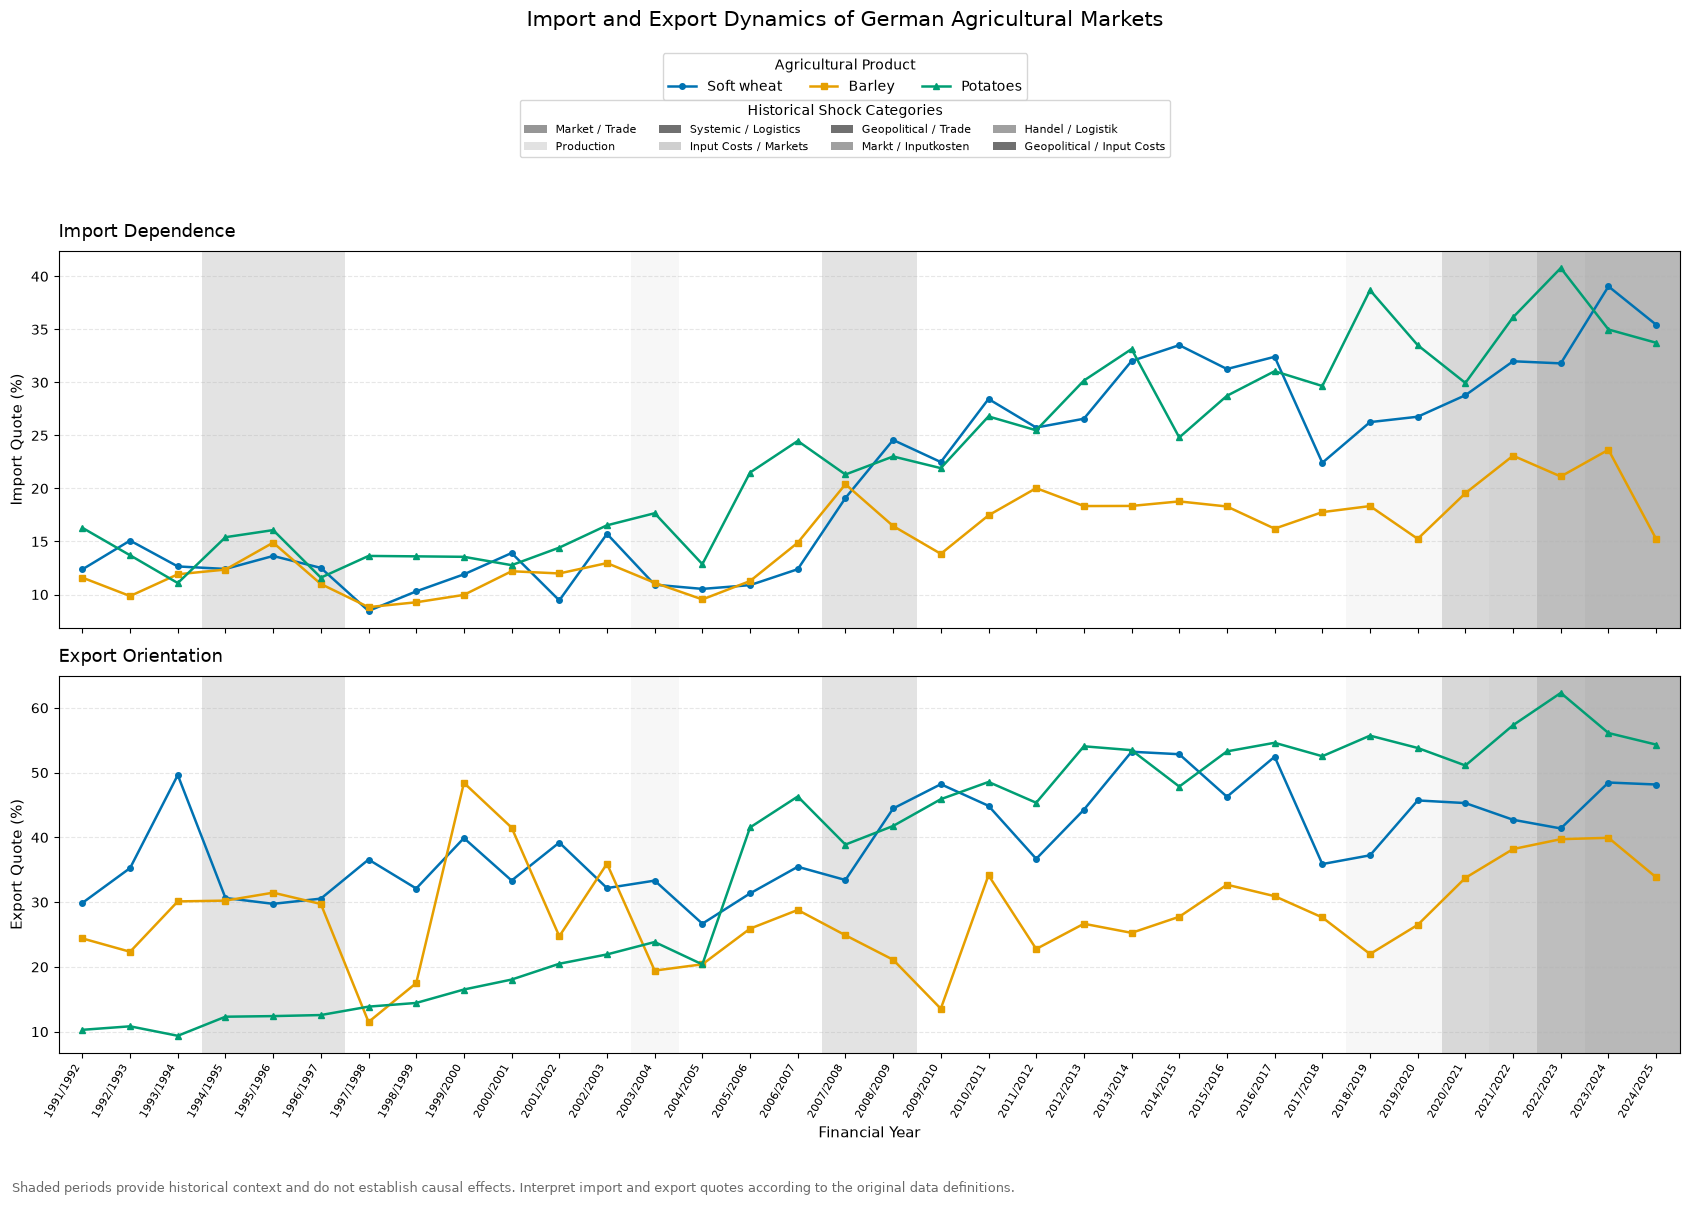

In [35]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ============================================================
# 1. PREPARE THE DATA
# ============================================================

trade_plot = analytical_df.copy()

# Extract the starting year from the financial-year label
trade_plot["Startjahr"] = (
    trade_plot["Wirtschaftsjahr"]
    .str.split("/")
    .str[0]
    .astype(int)
)

trade_plot = trade_plot.sort_values(
    ["Bilanz Produkt", "Startjahr"]
)

first_year = int(trade_plot["Startjahr"].min())
last_year = int(trade_plot["Startjahr"].max())
plot_end_year = last_year + 1

tick_years = np.arange(first_year, last_year + 1)

marketing_year_labels = [
    f"{year}/{year + 1}" for year in tick_years
]


# ============================================================
# 2. REUSE PRODUCT STYLES
# ============================================================

# Reuse product_styles from the previous figures if available

if "product_styles" not in globals():
    product_styles = {
        "Gerste": {
            "color": "#2878A5",
            "marker": "s",
            "markersize": 4,
            "linewidth": 1.8,
            "linestyle": "-",
            "label": "Barley",
        },
        "Kartoffeln": {
            "color": "#398564",
            "marker": "^",
            "markersize": 4,
            "linewidth": 1.8,
            "linestyle": "-",
            "label": "Potatoes",
        },
        "Weichweizen": {
            "color": "#D97732",
            "marker": "o",
            "markersize": 4,
            "linewidth": 1.8,
            "linestyle": "-",
            "label": "Soft Wheat",
        },
    }


# ============================================================
# 3. DEFINE HISTORICAL EVENT COLORS
# ============================================================

event_colors = {
    "Produktion": "#D9D9D9",
    "Markt/Preis": "#A6A6A6",
    "Markt / Preis": "#A6A6A6",
    "Markt / Handel": "#737373",
    "Handel/Lieferkette": "#737373",
    "Handel / Lieferkette": "#737373",
    "Inputkosten": "#BFBFBF",
    "Inputkosten / Energie": "#BFBFBF",
    "Finanziell": "#8C8C8C",
    "Politik/Institutionen": "#595959",
    "Politik / Institutionen": "#595959",
    "Geopolitisch/Systemisch": "#404040",
    "Geopolitisch / Systemisch": "#404040",
    "Strukturell / institutionell": "#A6A6A6",
    "Systemisch / Logistik": "#404040",
    "Geopolitisch / Handel": "#404040",
    "Geopolitisch / Inputkosten": "#404040",
    "Inputkosten / Markt": "#BFBFBF",
}

default_event_color = "#808080"

category_labels = {
    "Produktion": "Production",
    "Markt/Preis": "Market / Prices",
    "Markt / Preis": "Market / Prices",
    "Markt / Handel": "Market / Trade",
    "Handel/Lieferkette": "Trade / Supply Chain",
    "Handel / Lieferkette": "Trade / Supply Chain",
    "Inputkosten": "Input Costs",
    "Inputkosten / Energie": "Input Costs / Energy",
    "Finanziell": "Financial",
    "Politik/Institutionen": "Policy / Institutions",
    "Politik / Institutionen": "Policy / Institutions",
    "Geopolitisch/Systemisch": "Geopolitical / Systemic",
    "Geopolitisch / Systemisch": "Geopolitical / Systemic",
    "Strukturell / institutionell": "Structural / Institutional",
    "Systemisch / Logistik": "Systemic / Logistics",
    "Geopolitisch / Handel": "Geopolitical / Trade",
    "Geopolitisch / Inputkosten": "Geopolitical / Input Costs",
    "Inputkosten / Markt": "Input Costs / Markets",
}


def get_event_color(event_type):
    return event_colors.get(event_type, default_event_color)


# ============================================================
# 4. DEFINE THE TWO INDICATORS
# ============================================================

indicators = [
    {
        "column": "Importquote in %",
        "title": "Import Dependence",
        "ylabel": "Import Quote (%)",
    },
    {
        "column": "Exportquote in %",
        "title": "Export Orientation",
        "ylabel": "Export Quote (%)",
    },
]


# ============================================================
# 5. CREATE THE FIGURE
# ============================================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(17, 12),
    sharex=True,
)


# ============================================================
# 6. SHADE HISTORICAL SHOCK PERIODS
# ============================================================

# Apply identical event shading to both panels

for ax in axes:

    for event in events:

        if event.get("kind") not in ("shock", "ongoing"):
            continue

        start = max(int(event["start"]), first_year)
        end = min(int(event["end"]), last_year)

        if start > end:
            continue

        ax.axvspan(
            start,
            end + 1,
            color=get_event_color(event.get("type", "Other")),
            alpha=0.20,
            linewidth=0,
            zorder=0,
        )


# ============================================================
# 7. PLOT IMPORT AND EXPORT QUOTES
# ============================================================

for ax, indicator in zip(axes, indicators):

    column = indicator["column"]

    for product, style in product_styles.items():

        subset = trade_plot[
            trade_plot["Bilanz Produkt"] == product
        ].copy()

        subset = subset.dropna(
            subset=["Startjahr", column]
        ).sort_values("Startjahr")

        if subset.empty:
            continue

        ax.plot(
            subset["Startjahr"].astype(float) + 0.5,
            subset[column],
            color=style.get("color"),
            marker=style.get("marker", "o"),
            markersize=style.get("markersize", 4),
            linewidth=style.get("linewidth", 1.8),
            linestyle=style.get("linestyle", "-"),
            label=style.get("label", product),
            zorder=3,
        )

    ax.set_ylabel(indicator["ylabel"], fontsize=11)

    ax.set_title(
        indicator["title"],
        fontsize=13,
        loc="left",
        pad=10,
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3,
        zorder=1,
    )

    ax.set_axisbelow(True)


# ============================================================
# 8. FORMAT THE FINANCIAL-YEAR AXIS
# ============================================================

axes[-1].set_xticks(tick_years + 0.5)

axes[-1].set_xticklabels(
    marketing_year_labels,
    rotation=60,
    ha="right",
    fontsize=8,
)

for ax in axes:
    ax.set_xlim(first_year, plot_end_year)

axes[-1].set_xlabel("Financial Year", fontsize=11)


# ============================================================
# 9. CREATE THE LEGENDS
# ============================================================

# Product legend
product_handles = [
    plt.Line2D(
        [0],
        [0],
        color=style.get("color"),
        marker=style.get("marker", "o"),
        markersize=style.get("markersize", 4),
        linewidth=style.get("linewidth", 1.8),
        linestyle=style.get("linestyle", "-"),
        label=style.get("label", product),
    )
    for product, style in product_styles.items()
]

fig.legend(
    handles=product_handles,
    title="Agricultural Product",
    loc="upper center",
    bbox_to_anchor=(0.5, 0.965),
    ncol=3,
    frameon=True,
)


# Historical shock-category legend
categories_present = list(dict.fromkeys(
    event.get("type", "Other")
    for event in events
    if event.get("kind") in ("shock", "ongoing")
))

event_handles = [
    mpatches.Patch(
        facecolor=get_event_color(category),
        edgecolor="none",
        alpha=0.75,
        label=category_labels.get(category, category),
    )
    for category in categories_present
]

if event_handles:
    fig.legend(
        handles=event_handles,
        title="Historical Shock Categories",
        loc="upper center",
        bbox_to_anchor=(0.5, 0.925),
        ncol=4,
        fontsize=8,
        frameon=True,
    )


# ============================================================
# 10. ADD A METHODOLOGICAL NOTE
# ============================================================

fig.text(
    0.01,
    0.01,
    "Shaded periods provide historical context and do not "
    "establish causal effects. Interpret import and export "
    "quotes according to the original data definitions.",
    fontsize=9,
    color="dimgray",
)

fig.suptitle(
    "Import and Export Dynamics of German Agricultural Markets",
    fontsize=15,
    y=0.995,
)

plt.tight_layout(rect=[0, 0.04, 1, 0.86])
plt.show()


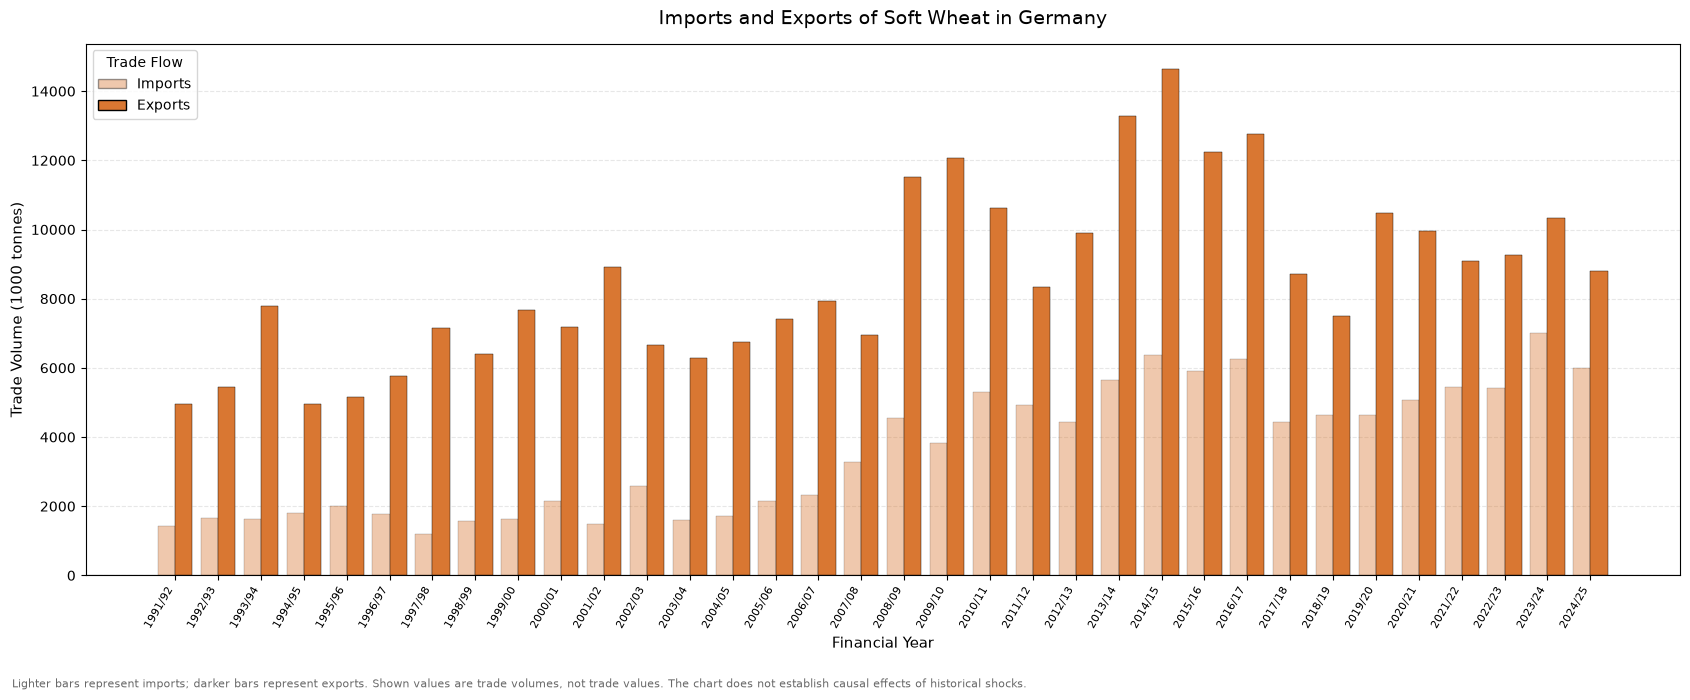

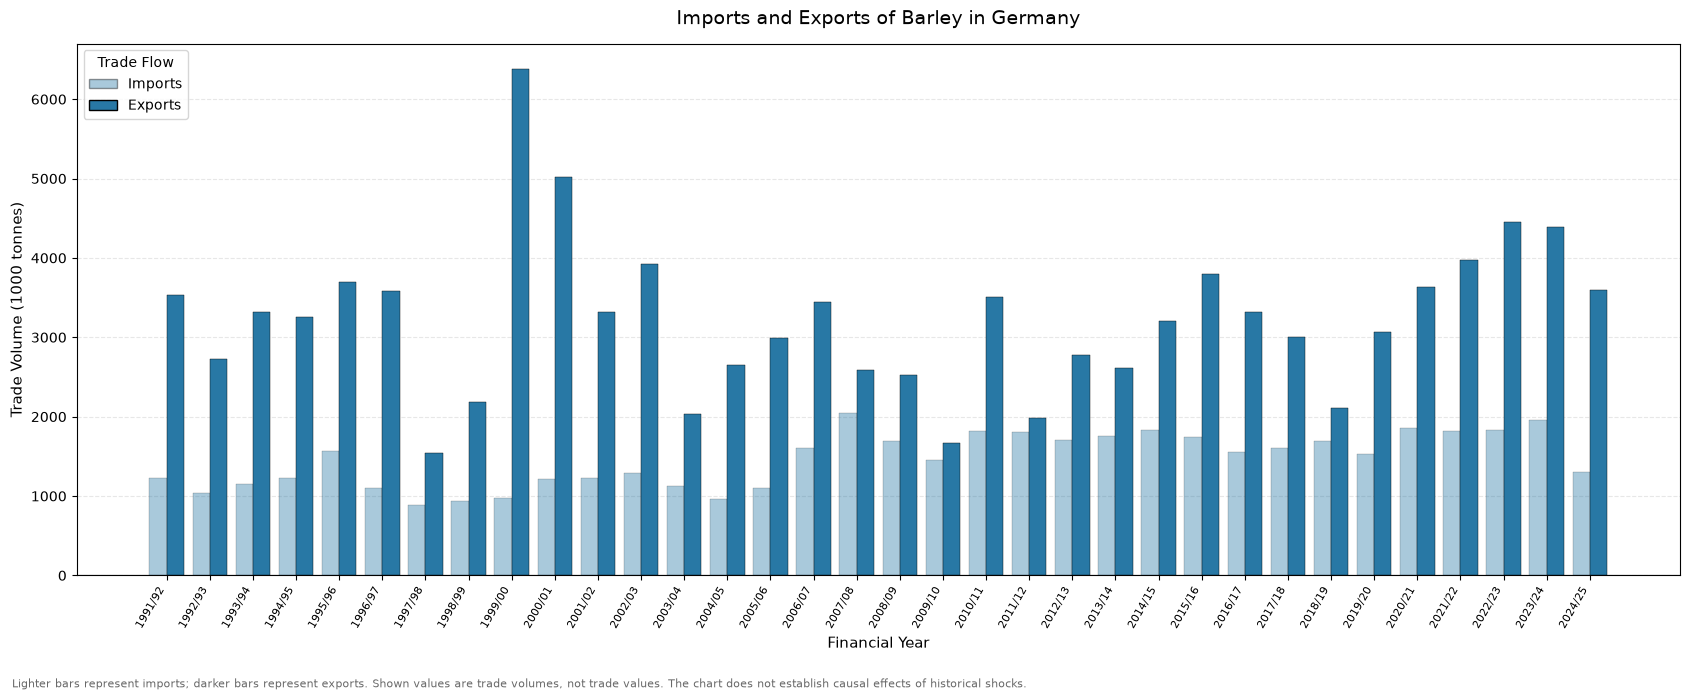

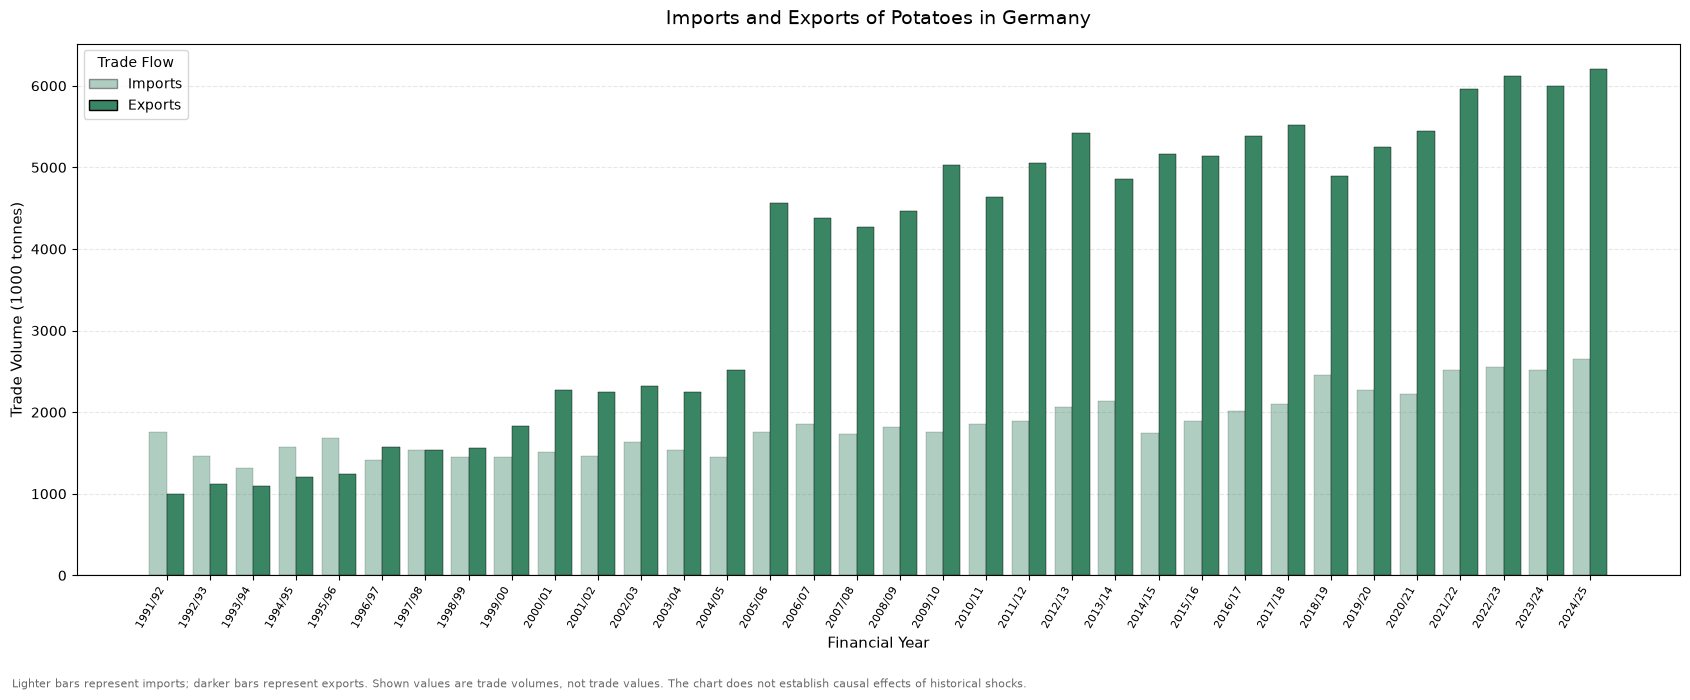

In [38]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ============================================================
# 1. PREPARE THE DATA
# ============================================================

# Use the existing analytical dataset
trade_plot = analytical_df.copy()

# Extract the starting calendar year of each financial year
trade_plot["Startjahr"] = (
    trade_plot["Wirtschaftsjahr"]
    .astype(str)
    .str.split("/")
    .str[0]
    .astype(int)
)

# Sort observations chronologically
trade_plot = trade_plot.sort_values(
    ["Bilanz Produkt", "Startjahr"]
)

# Define the observed time range
first_year = int(trade_plot["Startjahr"].min())
last_year = int(trade_plot["Startjahr"].max())

tick_years = np.arange(first_year, last_year + 1)

marketing_year_labels = [
    f"{year}/{str(year + 1)[-2:]}"
    for year in tick_years
]

# ============================================================
# 2. DEFINE THE EXISTING PRODUCT COLORS
# ============================================================

product_colors = {
    "Weichweizen": "#D97732",  # Orange
    "Gerste": "#2878A5",       # Blue
    "Kartoffeln": "#398564",   # Green
}

product_labels = {
    "Weichweizen": "Soft Wheat",
    "Gerste": "Barley",
    "Kartoffeln": "Potatoes",
}

# ============================================================
# 3. DEFINE IMPORT AND EXPORT STYLES
# ============================================================

# Imports: lighter version of each product color
# Exports: darker / fully saturated product color
import_alpha = 0.40
export_alpha = 1.00

# ============================================================
# 4. CREATE ONE FIGURE PER PRODUCT
# ============================================================

for product in ["Weichweizen", "Gerste", "Kartoffeln"]:

    subset = trade_plot[
        trade_plot["Bilanz Produkt"] == product
    ].copy()

    subset = subset.sort_values("Startjahr")

    # Remove observations without trade data
    subset = subset.dropna(
        subset=["Einfuhr", "Ausfuhr"]
    )

    if subset.empty:
        print(f"No trade data available for {product}.")
        continue

    # Position of each financial year
    x = np.arange(len(subset))
    bar_width = 0.40

    color = product_colors[product]

    # --------------------------------------------------------
    # Create the figure
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(17, 7))

    # --------------------------------------------------------
    # Plot imports and exports side by side
    # --------------------------------------------------------

    ax.bar(
        x - bar_width / 2,
        subset["Einfuhr"],
        width=bar_width,
        color=color,
        alpha=import_alpha,
        edgecolor="black",
        linewidth=0.3,
        label="Imports",
        zorder=3,
    )

    ax.bar(
        x + bar_width / 2,
        subset["Ausfuhr"],
        width=bar_width,
        color=color,
        alpha=export_alpha,
        edgecolor="black",
        linewidth=0.3,
        label="Exports",
        zorder=3,
    )

    # --------------------------------------------------------
    # Format the x-axis
    # --------------------------------------------------------

    ax.set_xticks(x)

    ax.set_xticklabels(
        subset["Wirtschaftsjahr"],
        rotation=60,
        ha="right",
        fontsize=8,
    )

    # --------------------------------------------------------
    # Format the axes and title
    # --------------------------------------------------------

    ax.set_xlabel("Financial Year", fontsize=11)
    ax.set_ylabel("Trade Volume (1000 tonnes)", fontsize=11)

    ax.set_title(
        f"Imports and Exports of {product_labels[product]} "
        "in Germany",
        fontsize=14,
        pad=14,
    )

    ax.axhline(
        0,
        color="black",
        linewidth=0.8,
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3,
        zorder=0,
    )

    ax.set_axisbelow(True)

    # --------------------------------------------------------
    # Add the legend
    # --------------------------------------------------------

    legend_handles = [
        mpatches.Patch(
            facecolor=color,
            alpha=import_alpha,
            edgecolor="black",
            label="Imports",
        ),
        mpatches.Patch(
            facecolor=color,
            alpha=export_alpha,
            edgecolor="black",
            label="Exports",
        ),
    ]

    ax.legend(
        handles=legend_handles,
        title="Trade Flow",
        loc="upper left",
        frameon=True,
    )

    # --------------------------------------------------------
    # Add the methodological note
    # --------------------------------------------------------

    fig.text(
        0.01,
        0.01,
        "Lighter bars represent imports; darker bars represent "
        "exports. Shown values are trade volumes, not trade values. "
        "The chart does not establish causal effects of historical shocks.",
        fontsize=8,
        color="dimgray",
    )

    plt.tight_layout(rect=[0, 0.04, 1, 1])
    plt.show()


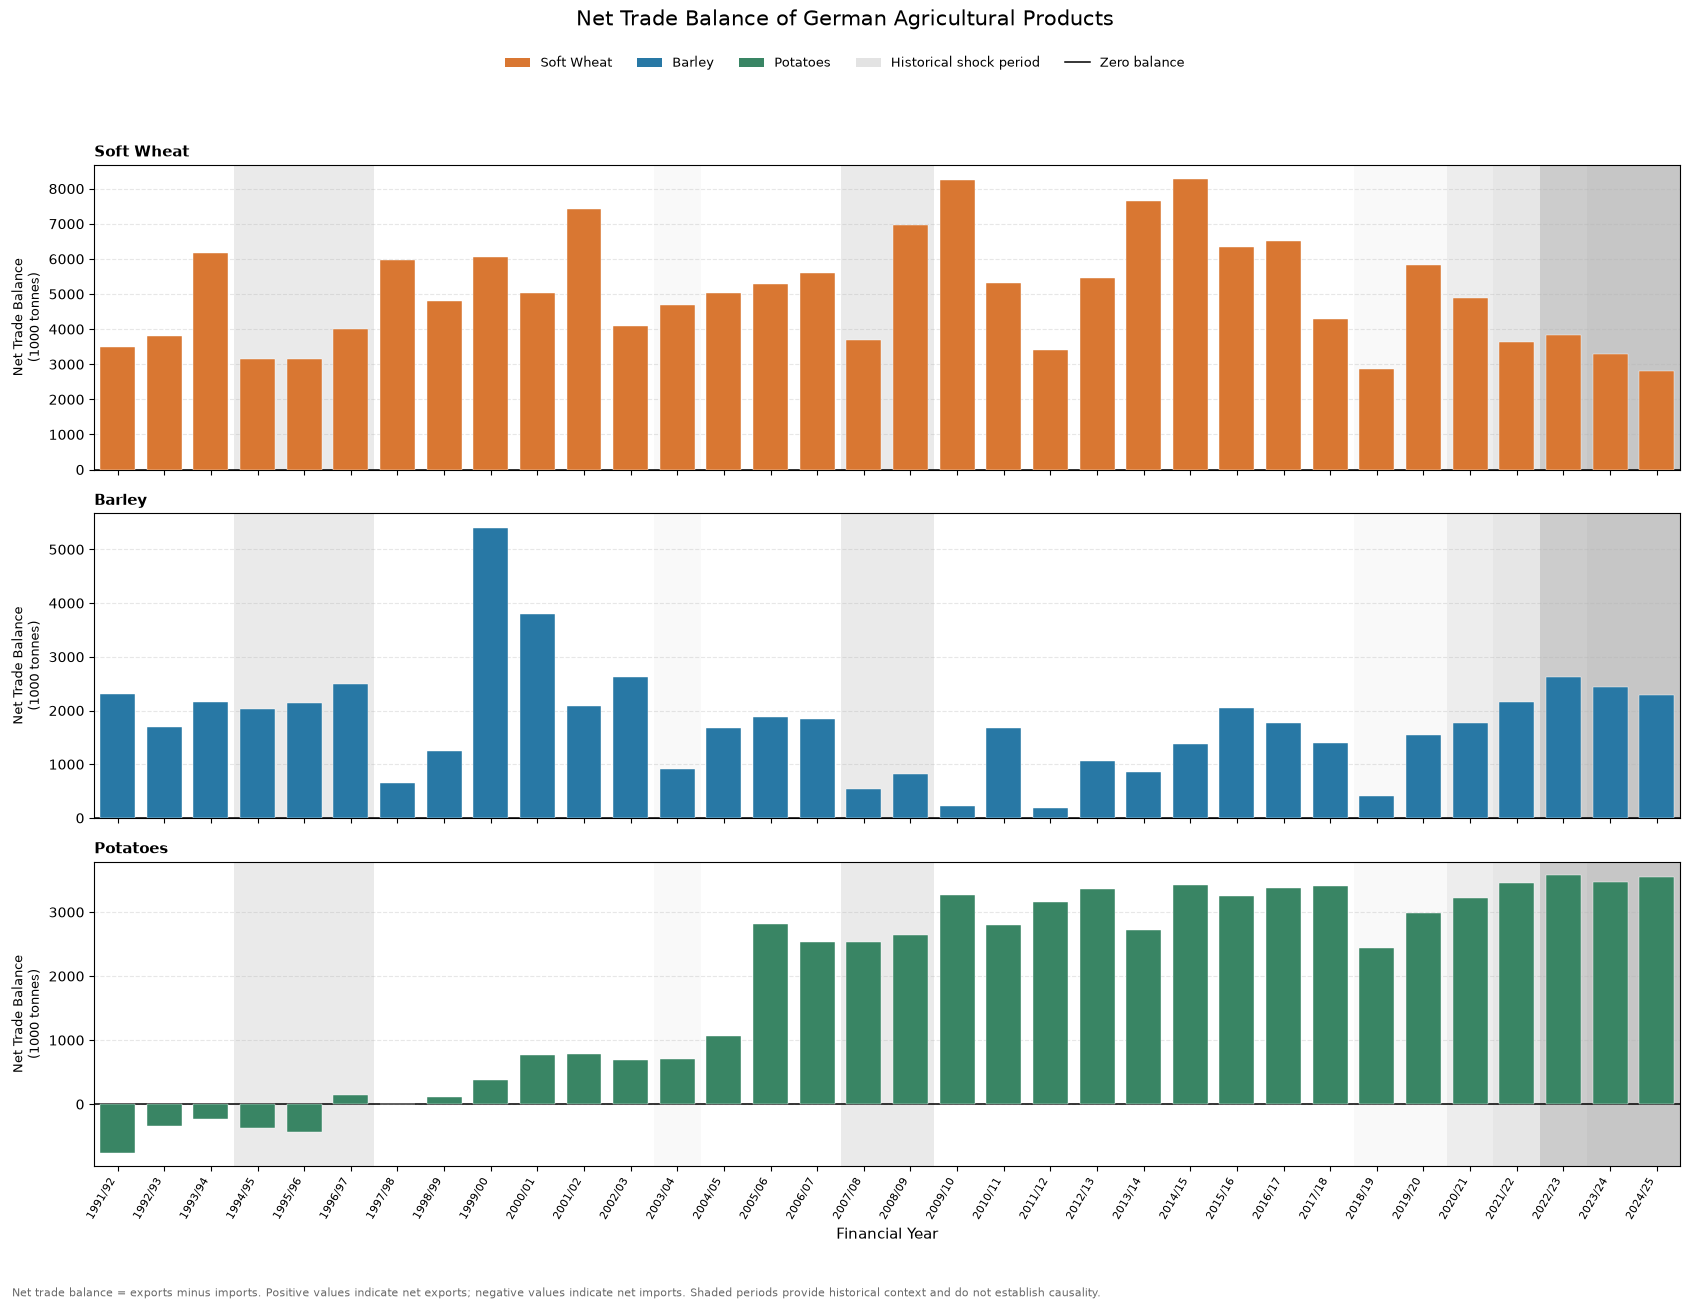

In [40]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ============================================================
# 1. PREPARE THE DATA
# ============================================================

# Create a copy of the analytical dataset
trade_balance_plot = analytical_df.copy()

# Extract the starting calendar year of each financial year
trade_balance_plot["Startjahr"] = (
    trade_balance_plot["Wirtschaftsjahr"]
    .astype(str)
    .str.split("/")
    .str[0]
    .astype(int)
)

# Calculate net trade balance as exports minus imports
trade_balance_plot["Calculated Net Trade Balance"] = (
    pd.to_numeric(trade_balance_plot["Ausfuhr"], errors="coerce")
    - pd.to_numeric(trade_balance_plot["Einfuhr"], errors="coerce")
)

# Sort observations chronologically
trade_balance_plot = trade_balance_plot.sort_values(
    ["Bilanz Produkt", "Startjahr"]
)

# Define the observed time range
first_year = int(trade_balance_plot["Startjahr"].min())
last_year = int(trade_balance_plot["Startjahr"].max())
plot_end_year = last_year + 1

tick_years = np.arange(first_year, last_year + 1)

marketing_year_labels = [
    f"{year}/{str(year + 1)[-2:]}"
    for year in tick_years
]

# ============================================================
# 2. DEFINE THE EXISTING PRODUCT COLORS
# ============================================================

product_colors = {
    "Weichweizen": "#D97732",
    "Gerste": "#2878A5",
    "Kartoffeln": "#398564",
}

product_labels = {
    "Weichweizen": "Soft Wheat",
    "Gerste": "Barley",
    "Kartoffeln": "Potatoes",
}

# ============================================================
# 3. DEFINE HISTORICAL EVENT COLORS
# ============================================================

# Reuse the event colors from the previous figures
event_colors = {
    "Produktion": "#D9D9D9",
    "Markt/Preis": "#A6A6A6",
    "Markt / Preis": "#A6A6A6",
    "Markt / Handel": "#737373",
    "Handel/Lieferkette": "#737373",
    "Handel / Lieferkette": "#737373",
    "Inputkosten": "#BFBFBF",
    "Inputkosten / Energie": "#BFBFBF",
    "Finanziell": "#8C8C8C",
    "Politik/Institutionen": "#595959",
    "Politik / Institutionen": "#595959",
    "Geopolitisch/Systemisch": "#404040",
    "Geopolitisch / Systemisch": "#404040",
    "Systemisch / Logistik": "#8C8C8C",
    "Geopolitisch / Handel": "#404040",
    "Geopolitisch / Inputkosten": "#404040",
    "Inputkosten / Markt": "#BFBFBF",
    "Strukturell / institutionell": "#A6A6A6",
}

default_event_color = "#808080"

# ============================================================
# 4. CREATE THREE PRODUCT-SPECIFIC PANELS
# ============================================================

products = ["Weichweizen", "Gerste", "Kartoffeln"]

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(17, 13),
    sharex=True,
)

for ax, product in zip(axes, products):

    subset = trade_balance_plot[
        trade_balance_plot["Bilanz Produkt"] == product
    ].copy()

    subset = subset.dropna(
        subset=["Startjahr", "Calculated Net Trade Balance"]
    )

    subset = subset.sort_values("Startjahr")

    # --------------------------------------------------------
    # Shade historical shock and ongoing-event periods
    # --------------------------------------------------------

    for event in events:

        if event.get("kind") not in ("shock", "ongoing"):
            continue

        start = max(int(event["start"]), first_year)
        end = min(int(event["end"]), last_year)

        if start > end:
            continue

        event_color = event_colors.get(
            event.get("type", "Other"),
            default_event_color,
        )

        ax.axvspan(
            start,
            end + 1,
            color=event_color,
            alpha=0.15,
            linewidth=0,
            zorder=0,
        )

    # --------------------------------------------------------
    # Plot the net trade balance
    # --------------------------------------------------------

    x = subset["Startjahr"].to_numpy(dtype=float) + 0.5
    balance = subset["Calculated Net Trade Balance"].to_numpy()

    ax.bar(
        x,
        balance,
        width=0.75,
        color=product_colors[product],
        edgecolor="white",
        linewidth=0.3,
        zorder=3,
    )

    # --------------------------------------------------------
    # Add the zero reference line
    # --------------------------------------------------------

    ax.axhline(
        0,
        color="black",
        linewidth=1.1,
        zorder=2,
    )

    # --------------------------------------------------------
    # Format each panel
    # --------------------------------------------------------

    ax.set_ylabel(
        "Net Trade Balance\n(1000 tonnes)",
        fontsize=9,
    )

    ax.set_title(
        product_labels[product],
        loc="left",
        fontsize=11,
        fontweight="bold",
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3,
        zorder=1,
    )

    ax.set_axisbelow(True)
    ax.set_xlim(first_year, plot_end_year)

# ============================================================
# 5. FORMAT THE SHARED TIME AXIS
# ============================================================

axes[-1].set_xticks(tick_years + 0.5)

axes[-1].set_xticklabels(
    marketing_year_labels,
    rotation=60,
    ha="right",
    fontsize=8,
)

axes[-1].set_xlabel("Financial Year", fontsize=11)

fig.suptitle(
    "Net Trade Balance of German Agricultural Products",
    fontsize=15,
    y=0.995,
)

# ============================================================
# 6. ADD A LEGEND FOR THE ZERO-LINE INTERPRETATION
# ============================================================

legend_handles = [
    mpatches.Patch(
        facecolor=product_colors[product],
        label=product_labels[product],
    )
    for product in products
]

legend_handles.extend([
    mpatches.Patch(
        facecolor="#B0B0B0",
        alpha=0.35,
        label="Historical shock period",
    ),
    plt.Line2D(
        [0], [0],
        color="black",
        linewidth=1.1,
        label="Zero balance",
    ),
])

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.968),
    ncol=5,
    frameon=False,
    fontsize=9,
)

# ============================================================
# 7. ADD THE METHODOLOGICAL NOTE
# ============================================================

fig.text(
    0.01,
    0.005,
    "Net trade balance = exports minus imports. Positive values "
    "indicate net exports; negative values indicate net imports. "
    "Shaded periods provide historical context and do not establish causality.",
    fontsize=8,
    color="dimgray",
)

plt.tight_layout(rect=[0, 0.035, 1, 0.93])
plt.show()


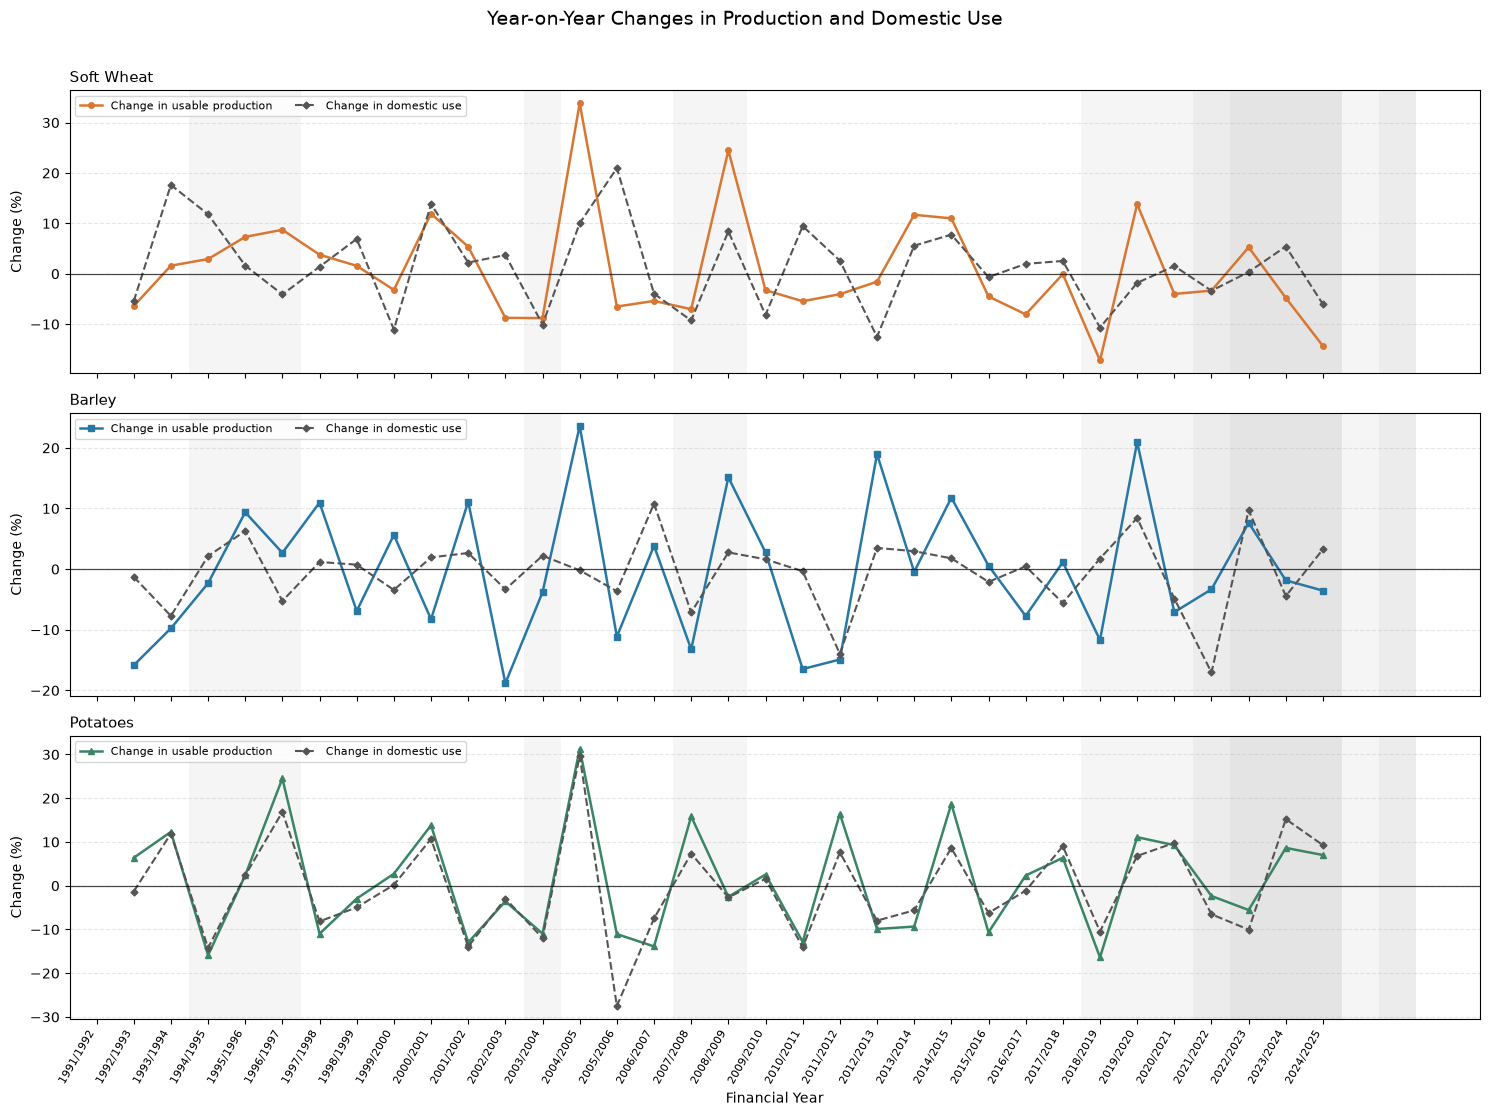

In [41]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Prepare data
# ------------------------------------------------------------
df = analytical_df.copy()

df["Startjahr"] = (
    df["Wirtschaftsjahr"]
    .str.split("/")
    .str[0]
    .astype(int)
)

df = df.sort_values(["Bilanz Produkt", "Startjahr"])

products = ["Weichweizen", "Gerste", "Kartoffeln"]

product_styles = {
    "Weichweizen": {"color": "#D97732", "marker": "o",
                    "label": "Soft Wheat"},
    "Gerste": {"color": "#2878A5", "marker": "s",
               "label": "Barley"},
    "Kartoffeln": {"color": "#398564", "marker": "^",
                   "label": "Potatoes"},
}

# ------------------------------------------------------------
# 2. Plot year-on-year changes
# ------------------------------------------------------------
fig, axes = plt.subplots(
    len(products), 1,
    figsize=(15, 11),
    sharex=True
)

for ax, product in zip(axes, products):
    subset = df[df["Bilanz Produkt"] == product].copy()

    subset = subset.dropna(subset=[
        "Erzeugungsänderung in %",
        "Inlandsverwendungsänderung in %"
    ])

    x = subset["Startjahr"].to_numpy(dtype=float) + 0.5
    style = product_styles[product]

    ax.plot(
        x,
        subset["Erzeugungsänderung in %"],
        color=style["color"],
        marker=style["marker"],
        linewidth=1.8,
        markersize=4,
        label="Change in usable production"
    )

    ax.plot(
        x,
        subset["Inlandsverwendungsänderung in %"],
        color="#555555",
        marker="D",
        linestyle="--",
        linewidth=1.5,
        markersize=3.5,
        label="Change in domestic use"
    )

    # Zero line: no year-on-year change
    ax.axhline(
        0, color="black", linewidth=0.9, alpha=0.7
    )

    ax.set_title(style["label"], loc="left", fontsize=11)
    ax.set_ylabel("Change (%)")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.legend(loc="upper left", fontsize=8, ncol=2)

    # Optional: shade shock and ongoing periods.
    # Requires the existing list "events".
    if "events" in globals():
        for event in events:
            if event.get("kind") not in ("shock", "ongoing"):
                continue

            start = int(event["start"])
            end = int(event["end"])

            ax.axvspan(
                start, end + 1,
                color="#B0B0B0",
                alpha=0.12,
                linewidth=0,
                zorder=0
            )

# Financial-year labels
first_year = int(df["Startjahr"].min())
last_year = int(df["Startjahr"].max())
tick_years = np.arange(first_year, last_year + 1)

axes[-1].set_xticks(tick_years + 0.5)
axes[-1].set_xticklabels(
    [f"{y}/{y+1}" for y in tick_years],
    rotation=60,
    ha="right",
    fontsize=8
)
axes[-1].set_xlabel("Financial Year")

fig.suptitle(
    "Year-on-Year Changes in Production and Domestic Use",
    fontsize=14,
    y=1.01
)

fig.tight_layout()
plt.show()


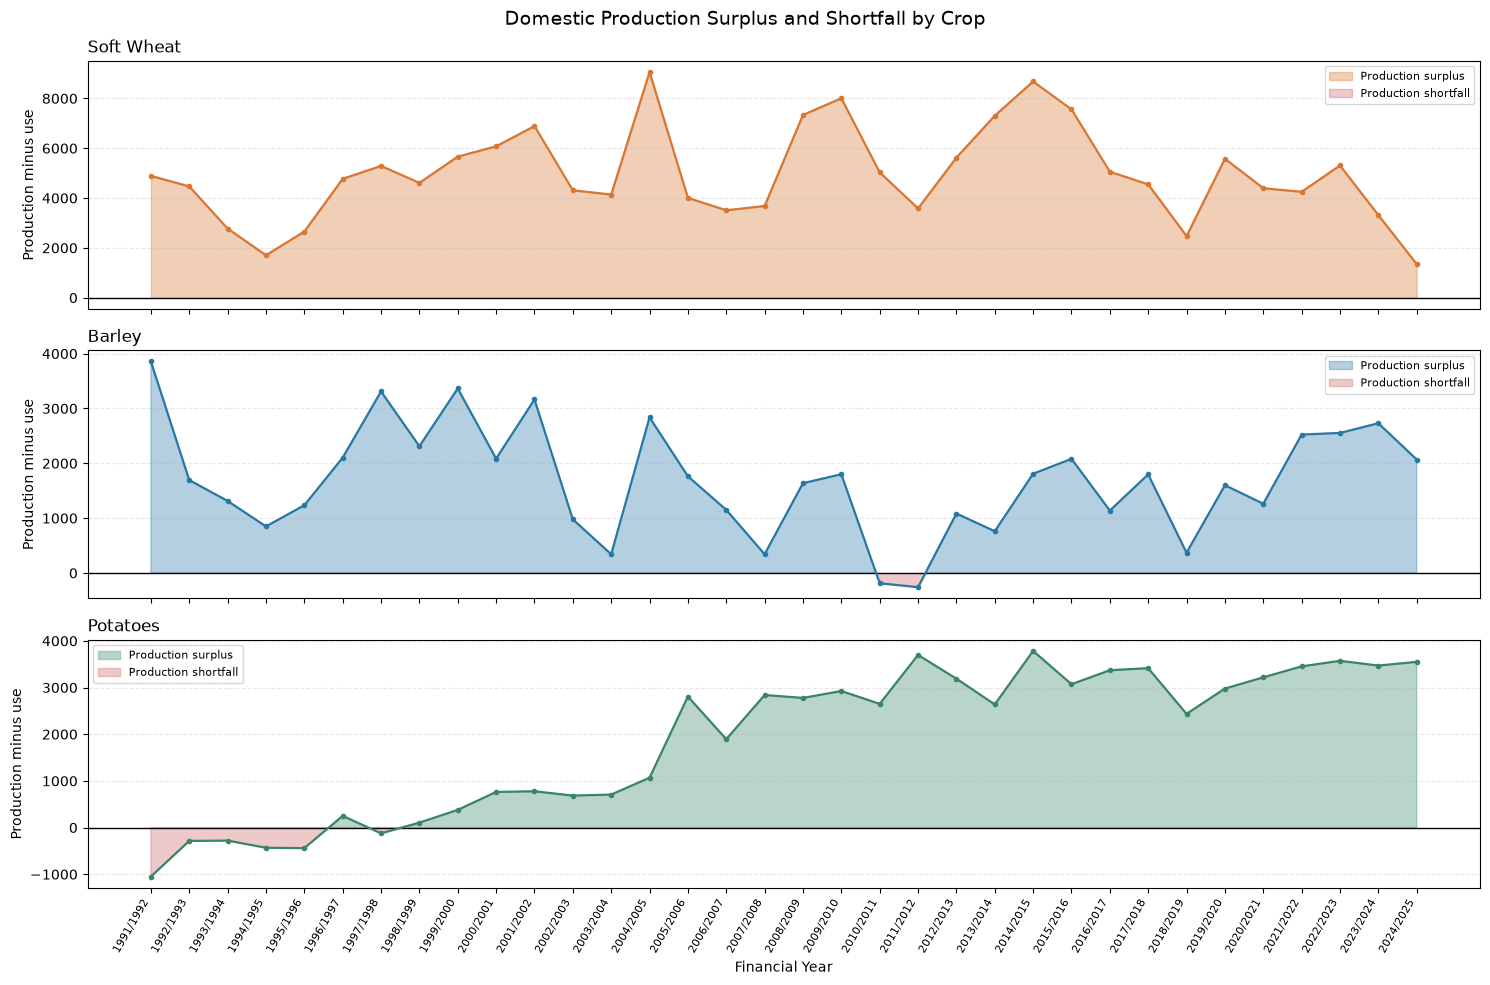

In [42]:

import numpy as np
import matplotlib.pyplot as plt

df = analytical_df.copy()

df["Startjahr"] = (
    df["Wirtschaftsjahr"]
    .str.split("/")
    .str[0]
    .astype(int)
)

# Ensure both variables use comparable units
df["Produktionssaldo"] = (
    df["Verwendbare Erzeugung"]
    - df["Inlandsverwendung standardisiert"]
)

products = ["Weichweizen", "Gerste", "Kartoffeln"]

styles = {
    "Weichweizen": {"color": "#D97732", "label": "Soft Wheat"},
    "Gerste": {"color": "#2878A5", "label": "Barley"},
    "Kartoffeln": {"color": "#398564", "label": "Potatoes"},
}

fig, axes = plt.subplots(
    3, 1, figsize=(15, 10), sharex=True
)

for ax, product in zip(axes, products):
    subset = (
        df[df["Bilanz Produkt"] == product]
        .dropna(subset=["Produktionssaldo"])
        .sort_values("Startjahr")
    )

    x = subset["Startjahr"].to_numpy(dtype=float) + 0.5
    y = subset["Produktionssaldo"].to_numpy()

    ax.axhline(0, color="black", linewidth=1)

    ax.fill_between(
        x, y, 0,
        where=(y >= 0),
        color=styles[product]["color"],
        alpha=0.35,
        interpolate=True,
        label="Production surplus"
    )

    ax.fill_between(
        x, y, 0,
        where=(y < 0),
        color="#C44E52",
        alpha=0.3,
        interpolate=True,
        label="Production shortfall"
    )

    ax.plot(
        x, y,
        color=styles[product]["color"],
        linewidth=1.6,
        marker="o",
        markersize=3
    )

    ax.set_title(styles[product]["label"], loc="left")
    ax.set_ylabel("Production minus use")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.legend(loc="best", fontsize=8)

first_year = int(df["Startjahr"].min())
last_year = int(df["Startjahr"].max())
years = np.arange(first_year, last_year + 1)

axes[-1].set_xticks(years + 0.5)
axes[-1].set_xticklabels(
    [f"{y}/{y+1}" for y in years],
    rotation=60, ha="right", fontsize=8
)
axes[-1].set_xlabel("Financial Year")

fig.suptitle(
    "Domestic Production Surplus and Shortfall by Crop",
    fontsize=14
)
fig.tight_layout()
plt.show()


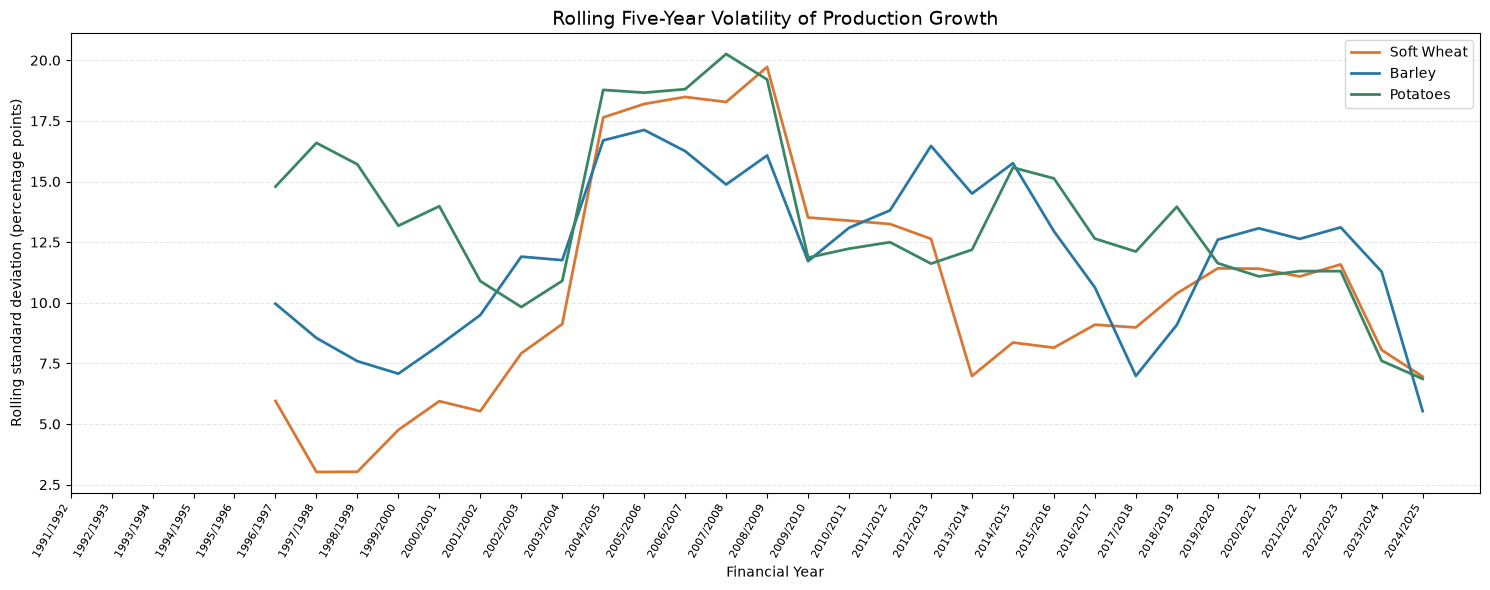

In [43]:

import numpy as np
import matplotlib.pyplot as plt

df = analytical_df.copy()

df["Startjahr"] = (
    df["Wirtschaftsjahr"]
    .str.split("/")
    .str[0]
    .astype(int)
)

df = df.sort_values(["Bilanz Produkt", "Startjahr"])

# Five-year rolling standard deviation of production growth
df["Erzeugungsvolatilitaet"] = (
    df.groupby("Bilanz Produkt")["Erzeugungsänderung in %"]
      .transform(
          lambda s: s.rolling(window=5, min_periods=5).std()
      )
)

styles = {
    "Weichweizen": {"color": "#D97732", "label": "Soft Wheat"},
    "Gerste": {"color": "#2878A5", "label": "Barley"},
    "Kartoffeln": {"color": "#398564", "label": "Potatoes"},
}

fig, ax = plt.subplots(figsize=(15, 6))

for product, style in styles.items():
    subset = (
        df[df["Bilanz Produkt"] == product]
        .dropna(subset=["Erzeugungsvolatilitaet"])
        .sort_values("Startjahr")
    )

    ax.plot(
        subset["Startjahr"].astype(float) + 0.5,
        subset["Erzeugungsvolatilitaet"],
        color=style["color"],
        linewidth=2,
        label=style["label"]
    )

ax.set_title(
    "Rolling Five-Year Volatility of Production Growth",
    fontsize=14
)
ax.set_xlabel("Financial Year")
ax.set_ylabel("Rolling standard deviation (percentage points)")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()

first_year = int(df["Startjahr"].min())
last_year = int(df["Startjahr"].max())
years = np.arange(first_year, last_year + 1)

ax.set_xticks(years + 0.5)
ax.set_xticklabels(
    [f"{y}/{y+1}" for y in years],
    rotation=60, ha="right", fontsize=8
)

plt.tight_layout()
plt.show()


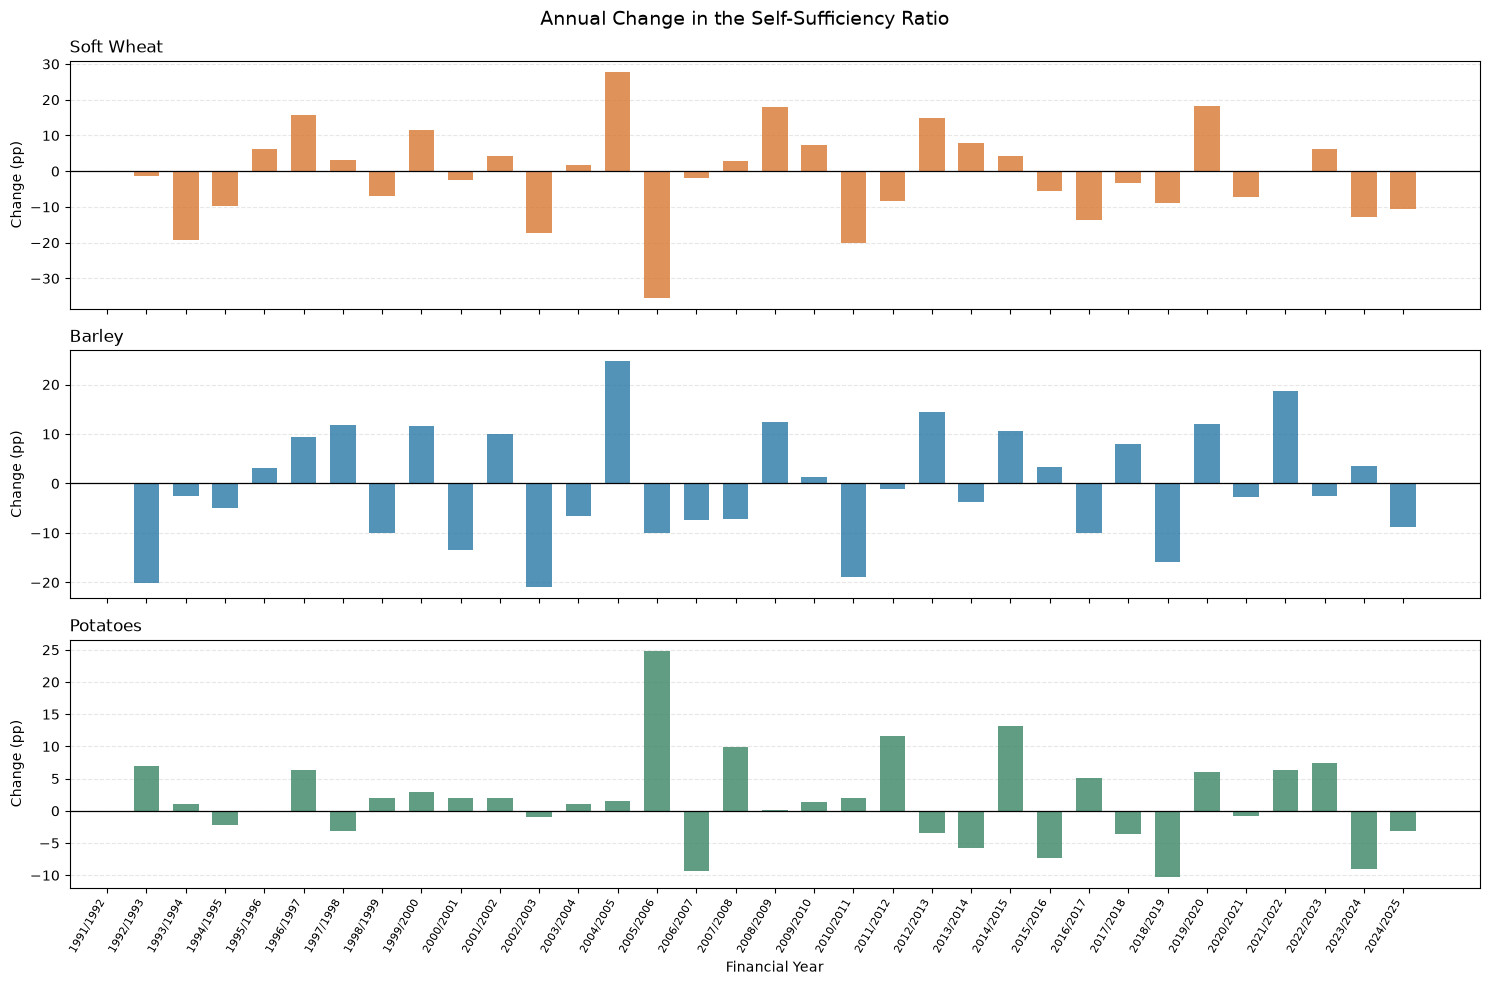

In [44]:

import numpy as np
import matplotlib.pyplot as plt

df = analytical_df.copy()

df["Startjahr"] = (
    df["Wirtschaftsjahr"]
    .str.split("/")
    .str[0]
    .astype(int)
)

df = df.sort_values(["Bilanz Produkt", "Startjahr"])

# Annual change in percentage points
df["SV-Grad Änderung (Prozentpunkte)"] = (
    df.groupby("Bilanz Produkt")["Selbstversorgungsgrad in %"]
      .diff()
)

styles = {
    "Weichweizen": {"color": "#D97732", "label": "Soft Wheat"},
    "Gerste": {"color": "#2878A5", "label": "Barley"},
    "Kartoffeln": {"color": "#398564", "label": "Potatoes"},
}

fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

for ax, (product, style) in zip(axes, styles.items()):
    subset = (
        df[df["Bilanz Produkt"] == product]
        .dropna(subset=["SV-Grad Änderung (Prozentpunkte)"])
        .sort_values("Startjahr")
    )

    x = subset["Startjahr"].to_numpy(dtype=float) + 0.5
    y = subset["SV-Grad Änderung (Prozentpunkte)"].to_numpy()

    ax.bar(
        x, y,
        width=0.65,
        color=style["color"],
        alpha=0.8
    )

    ax.axhline(0, color="black", linewidth=0.9)
    ax.set_title(style["label"], loc="left")
    ax.set_ylabel("Change (pp)")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

first_year = int(df["Startjahr"].min())
last_year = int(df["Startjahr"].max())
years = np.arange(first_year, last_year + 1)

axes[-1].set_xticks(years + 0.5)
axes[-1].set_xticklabels(
    [f"{y}/{y+1}" for y in years],
    rotation=60, ha="right", fontsize=8
)
axes[-1].set_xlabel("Financial Year")

fig.suptitle(
    "Annual Change in the Self-Sufficiency Ratio",
    fontsize=14
)

fig.tight_layout()
plt.show()


pp = Przentpunkte nicht Prozent %

Mögliche Reihenfolge für die Visualisierung

| Research Dimension | Recommended Visualisation | Economic Interpretation |
|---|---|---|
| Availability and Supply Balance | Time Series of Usable Production and Domestic Use | Tracks the development of domestic supply and demand over time. |
| Availability and Supply Balance | Production Surplus or Shortfall | Shows the extent to which domestic production exceeds or falls short of domestic use. |
| Trade Dependency | Imports, Exports, Net Trade and Trade Ratios | Assesses dependence on international markets and changes in trade patterns. |
| Price Stability | Price Trends and Price Volatility (if price data are available) | Examines price fluctuations and market responses to external shocks. |
| Adjustment and Recovery | Year-on-Year Changes in Production and Domestic Use | Measures the magnitude and timing of annual adjustments in supply and demand. |
| Adjustment and Recovery | Annual Change in the Self-Sufficiency Ratio | Tracks changes in the relative coverage of domestic use by domestic production. |
| Market Resilience | Rolling Volatility of Production Growth | Assesses the stability of production dynamics over time. |